# Tuberculose no Brasil, 2015–2025: perfil dos casos, impacto da pandemia e fatores associados ao desfecho desfavorável

**Disciplina:** Programação e Análise de Dados em Saúde — Prof. Lucas Miguel de Carvalho
**Grupo:** _[NOME DO GRUPO]_ — _[Integrante 1]_, _[Integrante 2]_
**Repositório:** _[https://github.com/USUARIO/tuberculose-sinan-brasil]_ — este notebook fica em `analytics/notebooks/`; o painel interativo está em `frontend/` (ver README).

---

## Sumário
0. Tema, objetivo e justificativa do dataset
1. Etapa 1 — Carregamento das bibliotecas e do dataset
2. Etapa 2 — Avaliação geral, manipulação e normalização dos dados
3. Etapa 3 — Visualização e interpretação
4. Etapa 4 — Funções próprias
5. Etapa 5 — Análises (A1: tendência e impacto da COVID-19; A2: fatores associados ao desfecho desfavorável)
6. Conclusões e limitações

## 0. Tema, objetivo e justificativa

**Tema:** epidemiologia e vigilância em saúde — **tuberculose (TB)**.

**Por que TB?** A tuberculose é uma doença curável, mas segue entre as infecções que mais matam no mundo. O Brasil está na lista da OMS de países prioritários para TB e TB/HIV, e o *Plano Nacional pelo Fim da Tuberculose como Problema de Saúde Pública* estabelece metas de redução de incidência e mortalidade até 2035. Dois indicadores operacionais acompanham o programa: a **proporção de cura** (meta ≥ 85%) e a **proporção de abandono** (meta ≤ 5%) entre casos novos. A pandemia de COVID‑19 desorganizou serviços de diagnóstico a partir de 2020, o que torna o período 2015–2025 especialmente interessante.

**Objetivo geral:** caracterizar os casos de TB notificados no Brasil entre 2015 e 2025 e identificar padrões relevantes para a vigilância.

**Perguntas de investigação**
1. **A1 —** Como evoluiu o número de casos novos de TB e qual foi o impacto da pandemia de COVID‑19 sobre as notificações?
2. **A2 —** Quais características sociodemográficas, clínicas e de vulnerabilidade estão associadas ao **desfecho desfavorável** (abandono ou óbito por TB) entre casos novos de TB pulmonar?

### Origem e descrição dos dados
- **Fonte:** Sistema de Informação de Agravos de Notificação (**SINAN**), Ministério da Saúde, disseminado pelo **DATASUS** (FTP público `ftp.datasus.gov.br/dissemin/publicos/SINAN/DADOS/`).
- **Arquivos:** `TUBEBR15.dbc` … `TUBEBR25.dbc` — um arquivo por **ano de diagnóstico**, cobertura nacional.
- **Status:** 2015–2019 estão na pasta **FINAIS** (base encerrada/consolidada); **2020–2025 são PRELIMINARES** — podem ser revisados e, nos anos mais recentes, muitos casos ainda não têm encerramento.
- **Unidade de observação:** uma **notificação** de TB (não necessariamente uma pessoa única: transferências e reingressos geram novas notificações).
- **Anonimização:** os microdados públicos não trazem nome, endereço ou número de documento. Mesmo assim, **os arquivos não são versionados no GitHub**; o README explica como baixá-los.

**Justificativa do dataset:** é a fonte oficial de vigilância da TB, tem cobertura nacional, ~1 milhão de registros e reúne variáveis sociodemográficas, clínicas, laboratoriais, de vulnerabilidade social e de desfecho do tratamento — o que permite responder às duas perguntas.

### Dicionário de dados (variáveis utilizadas)

| Variável SINAN | Nome no projeto | Descrição | Categorias / tipo |
|---|---|---|---|
| `DT_DIAG` | `dt_diag`, `ano_diag` | Data do diagnóstico | data |
| `SG_UF` | `uf`, `regiao` | UF de residência (código IBGE) | 11–53 |
| `NU_IDADE_N` | `idade` | Idade codificada: 1º dígito = unidade (1 hora, 2 dia, 3 mês, 4 ano), demais = valor | numérica (anos) |
| `CS_SEXO` | `sexo` | Sexo | M, F, I (ignorado) |
| `CS_RACA` | `raca` | Raça/cor | 1 Branca, 2 Preta, 3 Amarela, 4 Parda, 5 Indígena, 9 Ign. |
| `CS_ESCOL_N` | `escolaridade` | Escolaridade | 0 Analfabeto … 8 Superior completo, 9 Ign., 10 Não se aplica |
| `TRATAMENTO` | `tipo_entrada` | Tipo de entrada | 1 Caso novo, 2 Recidiva, 3 Reingresso após abandono, 4 Não sabe, 5 Transferência, 6 Pós‑óbito |
| `FORMA` | `forma` | Forma clínica | 1 Pulmonar, 2 Extrapulmonar, 3 Pulmonar + extrapulmonar |
| `AGRAVAIDS`, `AGRAVALCOO`, `AGRAVDIABE`, `AGRAVDOENC`, `AGRAVDROGA`, `AGRAVTABAC` | `aids`, `alcool`, `diabetes`, `doenca_mental`, `drogas`, `tabagismo` | Agravos associados | 1 Sim, 2 Não, 9 Ign. |
| `POP_RUA`, `POP_LIBER`, `POP_SAUDE`, `POP_IMIG` | `pop_rua`, `pop_liberdade`, `prof_saude`, `imigrante` | Populações especiais | 1 Sim, 2 Não, 9 Ign. |
| `BENEF_GOV` | `benef_gov` | Beneficiário de programa de transferência de renda | 1 Sim, 2 Não, 9 Ign. |
| `HIV` | `hiv_teste` | Resultado do teste de HIV | 1 Positivo, 2 Negativo, 3 Em andamento, 4 Não realizado |
| `BACILOSC_E` | `baciloscopia` | Baciloscopia de escarro (1ª amostra) | 1 Positiva, 2 Negativa, 3 Não realizada, 4 Não se aplica |
| `TEST_MOLEC` | `teste_molecular` | Teste rápido molecular (TRM‑TB) | 1 Detectável sensível à rifampicina, 2 Detectável resistente, 3 Não detectável, 4 Inconclusivo, 5 Não realizado |
| `DT_INIC_TR` | `dt_inicio` | Data de início do tratamento | data |
| `SITUA_ENCE` | `encerramento` | Situação de encerramento | 1 Cura, 2 Abandono, 3 Óbito por TB, 4 Óbito por outras causas, 5 Transferência, 6 Mudança de diagnóstico, 7 TB‑DR, 8 Mudança de esquema, 9 Falência, 10 Abandono primário |
| `DT_ENCERRA` | `dt_encerra` | Data de encerramento | data |

Variáveis **derivadas**: `faixa_etaria`, `regiao`, `caso_novo`, `pulmonar`, `tempo_trat_dias`, `desfecho_desfav` e `idade_z` (descritas na Etapa 2).

## 1. Etapa 1 — Carregamento das bibliotecas e do dataset

| Biblioteca | Para quê | Por que esta |
|---|---|---|
| `pyreaddbc` | Descompacta `.dbc` → `.dbf` | O `.dbc` é um formato proprietário do DATASUS (DBF comprimido); `pyreaddbc` é a implementação em Python do algoritmo usado pelo pacote R `read.dbc`. |
| `dbfread` | Lê o `.dbf` | Leitura simples e pura em Python, com controle do *encoding* (ISO‑8859‑1, padrão do DATASUS). |
| `pandas` / `numpy` | Manipulação e cálculo | Padrão para dados tabulares; operações vetorizadas em ~1 milhão de linhas. |
| `pyarrow` | Cache em Parquet | Ler 11 `.dbc` leva ~1,5 min; o Parquet guarda o resultado e é lido em segundos. |
| `matplotlib` / `seaborn` | Gráficos | `matplotlib` dá controle fino; `seaborn` simplifica histogramas, boxplots e mapas de calor. |
| `scipy.stats` | Testes estatísticos | Qui‑quadrado, regressão linear simples. |
| `statsmodels` | Modelos | Intervalo de predição da tendência (A1) e regressão logística (A2). |

In [ ]:
import os
import re
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from dbfread import DBF
from pyreaddbc import dbc2dbf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Identidade visual comum a todos os gráficos
CORES = {"azul": "#2a78d6", "laranja": "#eb6834", "verde_agua": "#1baf7a", "amarelo": "#eda100",
         "magenta": "#e87ba4", "verde": "#008300", "violeta": "#6250d6", "vermelho": "#e34948",
         "cinza": "#898781", "tinta": "#0b0b0b", "tinta2": "#52514e", "grade": "#e1e0d9"}
SERIE = [CORES[c] for c in ["azul", "laranja", "verde_agua", "amarelo", "magenta", "verde", "violeta", "vermelho"]]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": CORES["tinta2"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CORES["grade"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": CORES["tinta2"], "ytick.color": CORES["tinta2"], "font.size": 10,
    "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=SERIE), "legend.frameon": False,
})
FIG_DIR = Path("../figuras"); FIG_DIR.mkdir(exist_ok=True)
print("Bibliotecas carregadas. pandas", pd.__version__)

Bibliotecas carregadas. pandas 3.0.5


### 1.1 Leitura dos arquivos `.dbc`
A função `ler_dbc` descompacta cada arquivo em uma pasta temporária e lê o DBF. Todos os campos são lidos como **texto**: no SINAN quase tudo é código ("1", "2", "9"…), e a conversão para número/data é feita de forma explícita na Etapa 2. O resultado de cada ano é salvo em Parquet (`dados_processados/`) para que as próximas execuções sejam rápidas.

In [2]:
# Caminhos relativos a analytics/notebooks/ (no Docker vêm das variáveis de ambiente)
PASTA_DBC = Path(os.environ.get("TB_DADOS_BRUTOS", "../data/raw"))            # TUBEBRaa.dbc do DATASUS
PASTA_CACHE = Path(os.environ.get("TB_DADOS_PROCESSADOS", "../data/processed"))  # cache Parquet


def ler_dbc(caminho, encoding="iso-8859-1"):
    """Lê um .dbc do DATASUS e devolve um DataFrame com todas as colunas como texto."""
    caminho = Path(caminho)
    with tempfile.TemporaryDirectory() as tmp:
        dbf = str(Path(tmp) / (caminho.stem + ".dbf"))
        dbc2dbf(str(caminho), dbf)
        df = pd.DataFrame(iter(DBF(dbf, encoding=encoding, char_decode_errors="replace")))
    for c in df.columns:
        # A partir de 2018 alguns campos (idade, nº de contatos) vêm como numéricos no DBF:
        # 4052.0 -> 4052, para manter o mesmo formato de texto dos anos anteriores.
        if pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].astype("Int64")
        df[c] = df[c].astype("string").str.strip().replace("", pd.NA)
    return df


def carregar_sinan_tb(pasta_dbc=PASTA_DBC, pasta_cache=PASTA_CACHE):
    """Lê todos os TUBEBRaa.dbc (usando cache Parquet) e empilha os anos."""
    pasta_cache.mkdir(parents=True, exist_ok=True)
    partes = []
    for arq in sorted(Path(pasta_dbc).glob("TUBEBR*.dbc")):
        ano = 2000 + int(re.search(r"TUBEBR(\d{2})", arq.name).group(1))
        cache = pasta_cache / f"{arq.stem}.parquet"
        if cache.exists():
            parte = pd.read_parquet(cache)
        else:
            parte = ler_dbc(arq)
            parte.to_parquet(cache, index=False)
        parte["ARQUIVO_ANO"] = ano
        parte["STATUS_BASE"] = "final" if ano <= 2019 else "preliminar"
        partes.append(parte)
    if not partes:
        raise FileNotFoundError(f"Nenhum TUBEBR*.dbc encontrado em {pasta_dbc.resolve()}")
    return pd.concat(partes, ignore_index=True)


bruto = carregar_sinan_tb()
print(f"Dimensão do dataset bruto: {bruto.shape[0]:,} linhas × {bruto.shape[1]} colunas".replace(",", "."))

Dimensão do dataset bruto: 1.068.921 linhas × 99 colunas


### 1.2 Verificação do carregamento
Conferimos (i) quantos registros vieram de cada arquivo, (ii) se o ano do arquivo bate com o ano da data de diagnóstico e (iii) os nomes das variáveis e alguns exemplos de observações.

In [3]:
verif = (bruto.groupby(["ARQUIVO_ANO", "STATUS_BASE"]).size().rename("registros").reset_index())
ano_dt = pd.to_datetime(bruto["DT_DIAG"], errors="coerce").dt.year
verif["% com ano do diagnóstico = ano do arquivo"] = (
    (ano_dt == bruto["ARQUIVO_ANO"]).groupby(bruto["ARQUIVO_ANO"]).mean().values * 100)
verif

,ARQUIVO_ANO,STATUS_BASE,registros,% com ano do diagnóstico = ano do arquivo
0,2015,final,85462,100.00
1,2016,final,86210,100.00
2,2017,final,90295,100.00
3,2018,final,94735,100.00
4,2019,final,95849,100.00
5,2020,preliminar,86160,100.00
6,2021,preliminar,91415,100.00
7,2022,preliminar,103382,100.00
8,2023,preliminar,109919,100.00
9,2024,preliminar,113012,100.00


In [4]:
print("Variáveis (", bruto.shape[1], "):\n", ", ".join(bruto.columns))

Variáveis ( 99 ):
 TP_NOT, ID_AGRAVO, DT_NOTIFIC, NU_ANO, SG_UF_NOT, ID_MUNICIP, ID_REGIONA, DT_DIAG, ANO_NASC, NU_IDADE_N, CS_SEXO, CS_GESTANT, CS_RACA, CS_ESCOL_N, SG_UF, ID_MN_RESI, ID_RG_RESI, ID_PAIS, NDUPLIC_N, IN_VINCULA, DT_DIGITA, DT_TRANSUS, DT_TRANSDM, DT_TRANSSM, DT_TRANSRM, DT_TRANSRS, DT_TRANSSE, CS_FLXRET, FLXRECEBI, MIGRADO_W, ID_OCUPA_N, TRATAMENTO, INSTITUCIO, RAIOX_TORA, TESTE_TUBE, FORMA, EXTRAPU1_N, EXTRAPU2_N, EXTRAPUL_O, AGRAVAIDS, AGRAVALCOO, AGRAVDIABE, AGRAVDOENC, AGRAVOUTRA, AGRAVOUTDE, BACILOSC_E, BACILOS_E2, BACILOSC_O, CULTURA_ES, CULTURA_OU, HIV, HISTOPATOL, DT_INIC_TR, RIFAMPICIN, ISONIAZIDA, ETAMBUTOL, ESTREPTOMI, PIRAZINAMI, ETIONAMIDA, OUTRAS, OUTRAS_DES, TRAT_SUPER, NU_CONTATO, DOENCA_TRA, SG_UF_AT, ID_MUNIC_A, DT_NOTI_AT, SG_UF_2, ID_MUNIC_2, BACILOSC_1, BACILOSC_2, BACILOSC_3, BACILOSC_4, BACILOSC_5, BACILOSC_6, TRATSUP_AT, DT_MUDANCA, NU_COMU_EX, SITUA_9_M, SITUA_12_M, SITUA_ENCE, DT_ENCERRA, TPUNINOT, POP_LIBER, POP_RUA, POP_SAUDE, POP_IMIG, BENE

In [5]:
bruto.sample(5, random_state=42)[["ARQUIVO_ANO", "DT_DIAG", "SG_UF", "NU_IDADE_N", "CS_SEXO", "CS_RACA",
                                  "TRATAMENTO", "FORMA", "AGRAVAIDS", "AGRAVALCOO", "HIV", "SITUA_ENCE", "DT_ENCERRA"]]

,ARQUIVO_ANO,DT_DIAG,SG_UF,NU_IDADE_N,CS_SEXO,CS_RACA,TRATAMENTO,FORMA,AGRAVAIDS,AGRAVALCOO,HIV,SITUA_ENCE,DT_ENCERRA
979696,2025,2025-09-18,42,4007,F,1,3,1,2,2,2,<NA>,<NA>
672667,2022,2022-03-15,35,4020,M,1,1,1,2,2,<NA>,1,2022-09-30
363165,2019,2019-07-17,42,4022,M,1,1,1,2,2,2,1,2020-02-04
938941,2024,2024-10-09,31,4035,M,1,1,1,2,1,2,3,2024-10-20
309922,2018,2018-08-07,33,4027,M,4,1,1,2,2,4,2,2018-09-07


**O que a Etapa 1 mostra.** Foram lidos **11 arquivos** (2015–2025), totalizando **1.068.921 notificações e 97 variáveis** (+ 2 colunas de controle criadas por nós: `ARQUIVO_ANO` e `STATUS_BASE`). Em todos os anos, 100% dos registros têm data de diagnóstico no mesmo ano do arquivo, o que confirma que cada `TUBEBRaa` corresponde ao **ano de diagnóstico** e que a leitura não misturou arquivos. O volume anual cresce de ~85 mil (2015) para ~113 mil (2024–2025), com queda visível em 2020.

> ⚠️ **Atenção ao status da base:** apenas 2015–2019 são dados **finais**. Os arquivos de 2020–2025 estão na pasta **PRELIM** do DATASUS — ainda podem ser corrigidos pelos municípios e, sobretudo em 2024–2025, muitos casos ainda estão em tratamento e sem encerramento. Isso é levado em conta nas análises de desfecho.

## 2. Etapa 2 — Avaliação geral, manipulação e normalização

### 2.1 Tipos de variáveis
No arquivo bruto todas as colunas são texto (`string`). Conceitualmente, porém, elas se dividem em: **categóricas nominais** codificadas (sexo, raça, forma clínica, agravos, encerramento…), **categórica ordinal** (escolaridade), **numéricas** (idade, número de contatos) e **datas** (notificação, diagnóstico, início do tratamento, encerramento). Esse mapeamento orienta as conversões a seguir.

In [6]:
tipos = pd.Series({
    "datas": [c for c in bruto.columns if c.startswith("DT_")],
    "numéricas (após decodificação)": ["NU_IDADE_N", "ANO_NASC", "NU_CONTATO", "NU_COMU_EX"],
    "geográficas (códigos IBGE)": ["SG_UF_NOT", "ID_MUNICIP", "SG_UF", "ID_MN_RESI"],
})
tipos["categóricas codificadas"] = [c for c in bruto.columns
                                    if c not in sum(tipos.tolist(), []) + ["ARQUIVO_ANO", "STATUS_BASE"]]
for k, v in tipos.items():
    print(f"{k:32s} {len(v):3d} colunas  ex.: {', '.join(v[:6])}")
print("\ndtypes no bruto:", bruto.dtypes.astype(str).value_counts().to_dict())

datas                             13 colunas  ex.: DT_NOTIFIC, DT_DIAG, DT_DIGITA, DT_TRANSUS, DT_TRANSDM, DT_TRANSSM
numéricas (após decodificação)     4 colunas  ex.: NU_IDADE_N, ANO_NASC, NU_CONTATO, NU_COMU_EX
geográficas (códigos IBGE)         4 colunas  ex.: SG_UF_NOT, ID_MUNICIP, SG_UF, ID_MN_RESI
categóricas codificadas           76 colunas  ex.: TP_NOT, ID_AGRAVO, NU_ANO, ID_REGIONA, CS_SEXO, CS_GESTANT

dtypes no bruto: {'string': 97, 'int64': 1, 'str': 1}


### 2.2 Valores ausentes
No SINAN existem **três formas de "não informado"**: célula vazia (`NA`), o código **9 = Ignorado** e — nos arquivos de 2015 a 2017 — o código **0**, que não existe no dicionário e aparece exatamente onde, a partir de 2018, surge o campo vazio. Abaixo, o percentual de `NA` por coluna e a evidência do "0" como marcador de vazio.

In [7]:
ausentes = (bruto.isna().mean().mul(100).sort_values(ascending=False).rename("% NA").to_frame())
print("Colunas sem nenhum NA:", (ausentes["% NA"] == 0).sum(), "de", bruto.shape[1])
ausentes.head(15)

Colunas sem nenhum NA: 13 de 99


,% NA
DT_TRANSRM,100.00
FLXRECEBI,100.00
CS_FLXRET,100.00
EXTRAPUL_O,99.60
DT_TRANSDM,98.65
DT_TRANSRS,98.59
AGRAVOUTDE,97.76
MUN_TRANSF,95.66
DT_TRANSUS,95.52
UF_TRANSF,94.77


In [8]:
# O código "0" em CS_RACA (não previsto no dicionário) só aparece até 2017; depois, aparece NA
pd.crosstab(bruto["ARQUIVO_ANO"], bruto["CS_RACA"].fillna("NA"))[["0", "NA", "9"]].T

ARQUIVO_ANO,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
CS_RACA,,,,,,,,,,,
0,1102,1020,2254,0,0,0,0,0,0,0,0
NA,0,0,0,2263,2072,535,544,483,440,473,444
9,5761,6051,4546,4317,5063,6244,6732,6726,5109,5137,4887


### 2.3 Duplicatas
Os microdados não têm identificador de paciente, portanto não é possível ligar notificações da mesma pessoa. Verificamos **linhas inteiramente idênticas** (todas as 97 variáveis iguais), que só podem ser erro de digitação/exportação.

In [9]:
n_dup = bruto.duplicated().sum()
print(f"Linhas totalmente duplicadas: {n_dup}")
bruto = bruto.drop_duplicates().reset_index(drop=True)
print(f"Após remoção: {len(bruto):,} linhas".replace(",", "."))

Linhas totalmente duplicadas: 19


Após remoção: 1.068.902 linhas


### 2.4 Valores inconsistentes ou potencialmente inválidos

In [10]:
inconsist = {}
# Idade: unidade fora de {1,2,3,4} ou idade > 110 anos
unid = bruto["NU_IDADE_N"].str[0]
val = pd.to_numeric(bruto["NU_IDADE_N"].str[1:], errors="coerce")
inconsist["Idade com unidade inválida (≠1,2,3,4)"] = (~unid.isin(["1", "2", "3", "4"]) & unid.notna()).sum()
inconsist["Idade > 110 anos"] = ((unid == "4") & (val > 110)).sum()
# Datas fora do intervalo plausível
for c in ["DT_DIAG", "DT_INIC_TR", "DT_ENCERRA"]:
    d = pd.to_datetime(bruto[c], errors="coerce")
    inconsist[f"{c} fora de 2010–2026"] = ((d.dt.year < 2010) | (d.dt.year > 2026)).sum()
d_ini = pd.to_datetime(bruto["DT_INIC_TR"], errors="coerce")
d_enc = pd.to_datetime(bruto["DT_ENCERRA"], errors="coerce")
d_dia = pd.to_datetime(bruto["DT_DIAG"], errors="coerce")
inconsist["Encerramento antes do início do tratamento"] = (d_enc < d_ini).sum()
inconsist["Início do tratamento > 1 ano antes do diagnóstico"] = ((d_dia - d_ini).dt.days > 365).sum()
# Códigos fora do dicionário
inconsist["SITUA_ENCE com zero à esquerda ('03','04')"] = bruto["SITUA_ENCE"].isin(["03", "04"]).sum()
inconsist["UF de residência = 0"] = (bruto["SG_UF"] == "0").sum()
inconsist["Sexo ignorado (I)"] = (bruto["CS_SEXO"] == "I").sum()
inconsist["CID diferente de A16/A16.9"] = (~bruto["ID_AGRAVO"].isin(["A169", "A16."])).sum()
inconsist["Código '0' fora do dicionário (CS_RACA, 2015–2017)"] = (bruto["CS_RACA"] == "0").sum()
pd.Series(inconsist, name="registros").to_frame()

,registros
"Idade com unidade inválida (≠1,2,3,4)",35
Idade > 110 anos,12
DT_DIAG fora de 2010–2026,0
DT_INIC_TR fora de 2010–2026,4
DT_ENCERRA fora de 2010–2026,9
Encerramento antes do início do tratamento,2574
Início do tratamento > 1 ano antes do diagnóstico,9
"SITUA_ENCE com zero à esquerda ('03','04')",216
UF de residência = 0,116
Sexo ignorado (I),130


### 2.5 Manipulação e preparação
Procedimentos aplicados (e por quê):

1. **Seleção de colunas** — das 97 variáveis, mantemos ~30 ligadas às perguntas, reduzindo memória e ruído.
2. **Conversão de tipos** — datas com `pd.to_datetime(errors="coerce")`; datas fora de 2010–2026 viram `NaT` (são erros de digitação, como o ano 5017).
3. **Decodificação da idade** — `NU_IDADE_N` combina unidade e valor (ex.: `4052` = 52 anos; `3006` = 6 meses → 0 ano). Idades > 110 anos são consideradas inválidas.
4. **Recodificação de categorias** — códigos numéricos → rótulos legíveis; `'03'`/`'04'` → `'3'`/`'4'`; `0` (marcador de vazio em 2015–2017) → `NA`; `9 = Ignorado` mantido como categoria própria para medir completude, e convertido em `NA` nas variáveis binárias usadas em modelos.
5. **Criação de variáveis** — `regiao`, `faixa_etaria`, `caso_novo` (definição do Ministério da Saúde para incidência: caso novo + não sabe + pós‑óbito), `pulmonar`, `tempo_trat_dias` e `desfecho_desfav`.
6. **Exclusão** de registros encerrados como **mudança de diagnóstico** (não eram TB).

In [11]:
UF = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO", "21": "MA", "22": "PI",
      "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA", "31": "MG", "32": "ES",
      "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS", "50": "MS", "51": "MT", "52": "GO", "53": "DF"}
REGIAO = {"1": "Norte", "2": "Nordeste", "3": "Sudeste", "4": "Sul", "5": "Centro-Oeste"}
SIM_NAO = {"1": "Sim", "2": "Não", "9": "Ignorado"}
DIC = {
    "CS_SEXO": {"M": "Masculino", "F": "Feminino", "I": "Ignorado"},
    "CS_RACA": {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena", "9": "Ignorado"},
    "CS_ESCOL_N": {"0": "Até fund. incompleto", "1": "Até fund. incompleto", "2": "Até fund. incompleto",
                   "3": "Até fund. incompleto", "4": "Fund. completo / médio inc.", "5": "Fund. completo / médio inc.",
                   "6": "Médio completo ou mais", "7": "Médio completo ou mais", "8": "Médio completo ou mais",
                   "9": "Ignorado", "10": "Não se aplica"},
    "TRATAMENTO": {"1": "Caso novo", "2": "Recidiva", "3": "Reingresso após abandono", "4": "Não sabe",
                   "5": "Transferência", "6": "Pós-óbito"},
    "FORMA": {"1": "Pulmonar", "2": "Extrapulmonar", "3": "Pulmonar + extrapulmonar"},
    "HIV": {"1": "Positivo", "2": "Negativo", "3": "Em andamento", "4": "Não realizado"},
    "BACILOSC_E": {"1": "Positiva", "2": "Negativa", "3": "Não realizada", "4": "Não se aplica"},
    "TEST_MOLEC": {"1": "Detectável, sensível RIF", "2": "Detectável, resistente RIF", "3": "Não detectável",
                   "4": "Inconclusivo", "5": "Não realizado"},
    "SITUA_ENCE": {"1": "Cura", "2": "Abandono", "3": "Óbito por TB", "4": "Óbito por outras causas",
                   "5": "Transferência", "6": "Mudança de diagnóstico", "7": "TB-DR", "8": "Mudança de esquema",
                   "9": "Falência", "10": "Abandono primário"},
}
BINARIAS = {"AGRAVAIDS": "aids", "AGRAVALCOO": "alcool", "AGRAVDIABE": "diabetes", "AGRAVDOENC": "doenca_mental",
            "AGRAVDROGA": "drogas", "AGRAVTABAC": "tabagismo", "POP_RUA": "pop_rua", "POP_LIBER": "pop_liberdade",
            "POP_SAUDE": "prof_saude", "POP_IMIG": "imigrante", "BENEF_GOV": "benef_gov"}


def para_data(s):
    """Converte texto em data; anos fora de 2010–2026 viram NaT (erros de digitação)."""
    d = pd.to_datetime(s, errors="coerce")
    return d.where(d.dt.year.between(2010, 2026))


def decodificar_idade(s):
    """NU_IDADE_N -> idade em anos. Unidade 4 = anos; 1/2/3 (horas/dias/meses) = 0 ano; >110 = NA."""
    unidade, valor = s.str[0], pd.to_numeric(s.str[1:], errors="coerce").astype("Float64")
    idade = valor.where(unidade == "4")
    idade = idade.mask(unidade.isin(["1", "2", "3"]), 0)
    return idade.where(idade <= 110)


b = bruto  # apelido
tb = pd.DataFrame({
    "ano_diag": b["ARQUIVO_ANO"].astype(int),
    "status_base": b["STATUS_BASE"],
    "dt_diag": para_data(b["DT_DIAG"]),
    "dt_inicio": para_data(b["DT_INIC_TR"]),
    "dt_encerra": para_data(b["DT_ENCERRA"]),
    "uf": b["SG_UF"].map(UF),
    "regiao": b["SG_UF"].str[0].map(REGIAO).where(b["SG_UF"].isin(UF.keys())),
    "idade": decodificar_idade(b["NU_IDADE_N"]),
    "sexo": b["CS_SEXO"].map(DIC["CS_SEXO"]),
    "raca": b["CS_RACA"].map(DIC["CS_RACA"]),
    "escolaridade": b["CS_ESCOL_N"].map(DIC["CS_ESCOL_N"]),
    "tipo_entrada": b["TRATAMENTO"].map(DIC["TRATAMENTO"]),
    "forma": b["FORMA"].map(DIC["FORMA"]),
    "hiv_teste": b["HIV"].map(DIC["HIV"]),
    "baciloscopia": b["BACILOSC_E"].map(DIC["BACILOSC_E"]),
    "teste_molecular": b["TEST_MOLEC"].map(DIC["TEST_MOLEC"]),
    # '03'/'04' -> '3'/'4'; '0' (marcador de vazio em 2015-2017) vira NA porque não está no dicionário
    "encerramento": b["SITUA_ENCE"].str.lstrip("0").map(DIC["SITUA_ENCE"]),
})
for orig, novo in BINARIAS.items():
    tb[novo] = b[orig].map(SIM_NAO)   # códigos fora de {1,2,9} (ex.: '0') -> NA

# Variáveis derivadas
tb["faixa_etaria"] = pd.cut(tb["idade"].astype(float), bins=[-1, 14, 24, 34, 44, 54, 64, 200],
                            labels=["0–14", "15–24", "25–34", "35–44", "45–54", "55–64", "65+"])
tb["caso_novo"] = tb["tipo_entrada"].isin(["Caso novo", "Não sabe", "Pós-óbito"])
tb["pulmonar"] = tb["forma"].isin(["Pulmonar", "Pulmonar + extrapulmonar"])
tempo = (tb["dt_encerra"] - tb["dt_inicio"]).dt.days
tb["tempo_trat_dias"] = tempo.where(tempo.between(0, 730))   # fora de 0–2 anos = inconsistente
tb["desfecho_desfav"] = np.select(
    [tb["encerramento"].isin(["Abandono", "Abandono primário", "Óbito por TB"]), tb["encerramento"] == "Cura"],
    [1, 0], default=-1)
tb["desfecho_desfav"] = tb["desfecho_desfav"].replace(-1, np.nan)

# Na base pública o DATASUS já remove os casos encerrados como "mudança de diagnóstico";
# o filtro é mantido por segurança (e para documentar a regra) e deve excluir 0 registros.
n_mud = (tb["encerramento"] == "Mudança de diagnóstico").sum()
tb = tb[tb["encerramento"] != "Mudança de diagnóstico"].reset_index(drop=True)
cat_cols = ["status_base", "uf", "regiao", "sexo", "raca", "escolaridade", "tipo_entrada", "forma", "hiv_teste",
            "baciloscopia", "teste_molecular", "encerramento"] + list(BINARIAS.values())
tb[cat_cols] = tb[cat_cols].astype("category")
print(f"Excluídos por mudança de diagnóstico: {n_mud:,}".replace(",", "."))
print(f"Dataset preparado: {tb.shape[0]:,} linhas × {tb.shape[1]} colunas".replace(",", "."))
print(f"Memória: bruto {bruto.memory_usage(deep=True).sum()/1e9:.2f} GB -> preparado "
      f"{tb.memory_usage(deep=True).sum()/1e9:.2f} GB")
tb.head()

Excluídos por mudança de diagnóstico: 0
Dataset preparado: 1.068.902 linhas × 33 colunas
Memória: bruto 1.03 GB -> preparado 0.09 GB


,ano_diag,status_base,dt_diag,dt_inicio,dt_encerra,uf,regiao,idade,sexo,raca,escolaridade,tipo_entrada,forma,hiv_teste,baciloscopia,teste_molecular,encerramento,aids,alcool,diabetes,doenca_mental,drogas,tabagismo,pop_rua,pop_liberdade,prof_saude,imigrante,benef_gov,faixa_etaria,caso_novo,pulmonar,tempo_trat_dias,desfecho_desfav
0,2015,final,2015-02-26,2015-02-26,2015-04-10,PA,Norte,52.00,Masculino,Preta,Até fund. incompleto,Caso novo,Pulmonar,Negativo,Positiva,Não realizado,Cura,Não,Sim,Não,Não,Não,Não,Não,Não,Não,Não,Não,45–54,True,True,43.00,0.00
1,2015,final,2015-03-24,2015-03-24,2015-03-24,BA,Nordeste,33.00,Feminino,Parda,Até fund. incompleto,Caso novo,Pulmonar,Não realizado,Positiva,Não realizado,Cura,Não,Não,Não,Não,Não,Não,Não,Não,Não,Não,Ignorado,25–34,True,True,0.00,0.00
2,2015,final,2015-10-02,2015-10-05,2015-10-05,SC,Sul,27.00,Feminino,Branca,Médio completo ou mais,Caso novo,Pulmonar,Negativo,Positiva,Não realizado,Cura,Não,Não,Não,Não,Não,Não,Não,Não,Não,Não,Não,25–34,True,True,0.00,0.00
3,2015,final,2015-10-14,2015-10-16,2015-10-17,PR,Sul,50.00,Masculino,Branca,Até fund. incompleto,Caso novo,Pulmonar,Negativo,Negativa,Não realizado,Cura,Não,Não,Não,Não,Não,Não,Não,Não,Não,Não,Não,45–54,True,True,1.00,0.00
4,2015,final,2015-01-10,2015-04-24,2015-10-26,PR,Sul,50.00,Masculino,Branca,Até fund. incompleto,Caso novo,Pulmonar,Negativo,Negativa,Não realizado,Cura,Não,Não,Não,Não,Não,Sim,Não,Não,Não,Não,Não,45–54,True,True,185.00,0.00


### 2.6 Estatísticas descritivas

In [12]:
print("Idade (anos) — todos os registros")
desc_idade = tb["idade"].astype(float).describe(percentiles=[.05, .25, .5, .75, .95])
print(desc_idade.round(1).to_string())
print(f"Assimetria: {tb['idade'].astype(float).skew():.2f} | Curtose: {tb['idade'].astype(float).kurt():.2f}")
tb.groupby("sexo", observed=True)["idade"].agg(["count", "mean", "median", "std"]).round(1)

Idade (anos) — todos os registros
count   1,068,530.00
mean           40.20
std            17.10
min             0.00
5%             17.00
25%            27.00
50%            38.00
75%            52.00
95%            71.00
max           110.00
Assimetria: 0.43 | Curtose: -0.27


,count,mean,median,std
sexo,,,,
Feminino,319658,40.20,38.00,18.40
Ignorado,129,39.40,37.00,15.20
Masculino,748743,40.20,38.00,16.60


In [13]:
def freq(col, dados=tb):
    t = dados[col].value_counts(dropna=False)
    return pd.DataFrame({"n": t, "%": (t / t.sum() * 100).round(1)})

pd.concat({c: freq(c) for c in ["sexo", "raca", "tipo_entrada", "forma", "encerramento"]})

n     %
sexo         Masculino                 749008 70.10
             Feminino                  319764 29.90
             Ignorado                     130  0.00
raca         Parda                     536159 50.20
             Branca                    296516 27.70
             Preta                     143968 13.50
             Ignorado                   60566  5.70
             nan                        11631  1.10
             Indígena                   10574  1.00
             Amarela                     9488  0.90
tipo_entrada Caso novo                 837817 78.40
             Reingresso após abandono  112053 10.50
             Recidiva                   77541  7.30
             Transferência              28998  2.70
             Pós-óbito                   7586  0.70
             Não sabe                    4907  0.50
forma        Pulmonar                  907419 84.90
             Extrapulmonar             127238 11.90
             Pulmonar + extrapulmonar   33918  3.20
             nan                          327  0.00
encerramento Cura                      652093 61.00
             Abandono                  153423 14.40
             nan                        74771  7.00
             Transferência              69889  6.50
             Óbito por outras causas    45136  4.20
             Óbito por TB               42597  4.00
             TB-DR                      11329  1.10
             Abandono primário           9715  0.90
             Mudança de esquema          8815  0.80
             Falência                    1134  0.10

### 2.7 Normalização: padronização da idade por escore Z
Na regressão logística (A2) a idade entra como variável contínua. Padronizamos por **escore Z** (`(x − média) / desvio‑padrão`) para que o coeficiente seja interpretado como "variação na chance a cada **1 desvio‑padrão** de idade" e fique na mesma escala das demais variáveis. Escolhemos Z em vez de Min‑Max porque a idade tem caudas longas (até 110 anos): o Min‑Max ficaria dominado por poucos valores extremos, enquanto o Z usa a média e o desvio de toda a distribuição.

In [14]:
mu, sd = tb["idade"].astype(float).mean(), tb["idade"].astype(float).std()
tb["idade_z"] = (tb["idade"].astype(float) - mu) / sd
print(f"Média = {mu:.2f} anos; DP = {sd:.2f} anos")
print(tb["idade_z"].describe().round(3).to_string())
print("Exemplo: 60 anos ->", round((60 - mu) / sd, 2), "DP acima da média")

Média = 40.18 anos; DP = 17.15 anos


count   1,068,530.00
mean            0.00
std             1.00
min            -2.34
25%            -0.77
50%            -0.13
75%             0.69
max             4.07
Exemplo: 60 anos -> 1.16 DP acima da média


**Resumo da Etapa 2.**
- **Tipos:** 97 variáveis lidas como texto; 13 datas, 4 numéricas codificadas, 4 geográficas e 76 categóricas codificadas. Um detalhe técnico encontrado: a partir de 2018 o DATASUS passou a gravar idade e nº de contatos como campos **numéricos** no DBF (ex.: `4052.0`), enquanto até 2017 eram texto (`4052`). A função de leitura padroniza os dois formatos.
- **Ausentes:** 86 das 99 colunas têm algum `NA`; campos administrativos de transferência (`DT_TRANSRM`, `FLXRECEBI`…) estão quase 100% vazios e foram descartados. Nas variáveis de interesse, o maior problema é o código **9 = Ignorado** (ex.: 22% em escolaridade), avaliado em detalhe pela Função 1 (Etapa 4). O código **0**, que não existe no dicionário, é o marcador de vazio dos arquivos de 2015–2017 e foi convertido em `NA`.
- **Duplicatas:** 19 linhas idênticas em todas as variáveis foram removidas. Como não há identificador de pessoa, **não é possível** detectar a mesma pessoa notificada duas vezes (ex.: transferência) — por isso as análises de incidência usam apenas **casos novos**.
- **Inconsistências:** 2.574 registros com encerramento antes do início do tratamento, datas impossíveis (ex.: ano 5017), 216 códigos de encerramento com zero à esquerda, 116 UFs = 0 e 47 idades inválidas. Foram tratados como ausentes, sem excluir o registro inteiro (para não perder as demais informações).
- **Descritivas:** idade média 40,2 anos (DP 17,1; mediana 38), distribuição levemente assimétrica à direita (assimetria 0,43); **70% homens**; 50% pardos, 28% brancos e 14% pretos; 85% pulmonares; 78% casos novos e **10,5% reingressos após abandono**.
- **Normalização:** idade padronizada por escore Z (média 0, DP 1), usada na regressão da A2.

## 3. Etapa 3 — Visualização e interpretação
Recortes usados: **casos novos** (definição do MS) para perfil e tendência; **casos novos de TB pulmonar diagnosticados entre 2015 e 2023** para desfechos (2024–2025 ainda têm muitos casos sem encerramento — ver Gráfico 5).

In [15]:
novos = tb[tb["caso_novo"]]
coorte = tb[tb["caso_novo"] & tb["pulmonar"] & tb["ano_diag"].between(2015, 2023)]
print(f"Casos novos: {len(novos):,} | Coorte de desfecho (pulmonares, 2015–2023): {len(coorte):,}".replace(",", "."))

Casos novos: 850.310 | Coorte de desfecho (pulmonares. 2015–2023): 590.841


### Gráfico 1 — Linhas: notificações por ano e tipo de entrada
**Pergunta:** como o volume de notificações variou entre 2015 e 2025, e a variação é igual para casos novos, recidivas e reingressos?
**Por que linhas:** a variável no eixo x é tempo (ano); linhas mostram tendência e quebras, e permitem comparar várias séries na mesma escala.

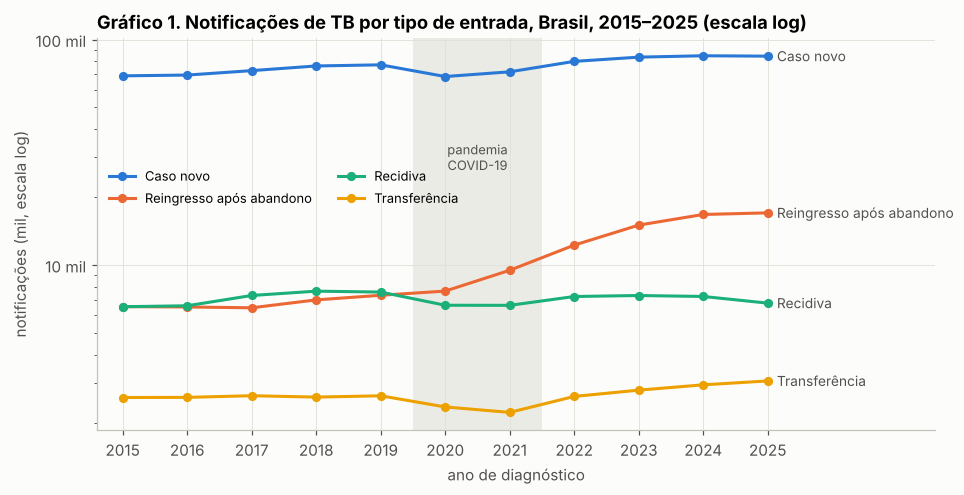

tipo_entrada,Caso novo,Recidiva,Reingresso após abandono,Transferência
ano_diag,,,,
2020,-11.30,-12.60,4.40,-10.80
2021,4.90,-0.10,23.70,-5.40
2022,11.20,9.40,29.30,17.70
2023,4.40,1.00,22.70,6.60
2024,1.40,-1.00,11.50,5.60
2025,-0.40,-6.60,1.70,4.00


In [16]:
serie = (tb[tb["tipo_entrada"].isin(["Caso novo", "Recidiva", "Reingresso após abandono", "Transferência"])]
         .groupby(["ano_diag", "tipo_entrada"], observed=True).size().unstack())
fig, ax = plt.subplots(figsize=(9, 4.6))
for i, col in enumerate(["Caso novo", "Reingresso após abandono", "Recidiva", "Transferência"]):
    ax.plot(serie.index, serie[col] / 1000, marker="o", ms=5, color=SERIE[i], label=col)
    ax.annotate(col, (serie.index[-1], serie[col].iloc[-1] / 1000), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=CORES["tinta2"])
ax.axvspan(2019.5, 2021.5, color=CORES["grade"], alpha=.6, lw=0)
ax.text(2020.5, 30, "pandemia\nCOVID-19", ha="center", va="center", fontsize=8.5, color=CORES["tinta2"])
ax.set_yscale("log"); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g} mil"))
ax.set_xticks(serie.index); ax.set_xlim(2014.6, 2027.6)
ax.set_title("Gráfico 1. Notificações de TB por tipo de entrada, Brasil, 2015–2025 (escala log)")
ax.set_ylabel("notificações (mil, escala log)"); ax.set_xlabel("ano de diagnóstico")
ax.legend(loc="center left", bbox_to_anchor=(0, .62), ncol=2, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG_DIR / "g1_serie_tipo_entrada.png"); plt.show()
(serie.pct_change() * 100).round(1).loc[[2020, 2021, 2022, 2023, 2024, 2025]]

**Padrões observados.**
- **Casos novos** cresciam de forma constante até 2019, **caíram 11,3% em 2020** e só superaram o patamar de 2019 em 2022 (+11,2%). Em 2024–2025 estão estáveis em ~86 mil/ano.
- **Recidivas** e **transferências** acompanharam a queda de 2020 (−12,6% e −10,8%).
- O destaque é o **reingresso após abandono**: foi a única série que **cresceu em 2020** (+4,4%) e disparou depois (+23,7% em 2021, +29,3% em 2022), passando de **7,3 mil (2019) para 17,0 mil (2025)** — de 7,7% para 15,1% de todas as notificações.

**Interpretação.** A queda de 2020 é compatível com a desorganização dos serviços durante a pandemia (menos busca ativa, menor acesso a exames, profissionais deslocados para a COVID‑19), mais do que com uma queda real da transmissão — hipótese testada na **A1**. O crescimento dos reingressos indica que mais pessoas interromperam o tratamento e voltaram ao sistema, o que conversa com o aumento do abandono visto no Gráfico 5. **Limitação:** são contagens absolutas, sem ajuste pelo tamanho da população; e a escala log foi usada apenas para que as quatro séries (que diferem em ~30×) fiquem legíveis no mesmo painel.

### Gráfico 2 — Histograma: distribuição etária dos casos novos por sexo
**Pergunta:** qual a distribuição da idade dos casos novos e ela difere entre homens e mulheres?
**Por que histograma:** idade é numérica contínua; o histograma mostra forma, moda e assimetria. Sobrepor os dois sexos (com contorno, sem empilhar) permite comparar formatos.

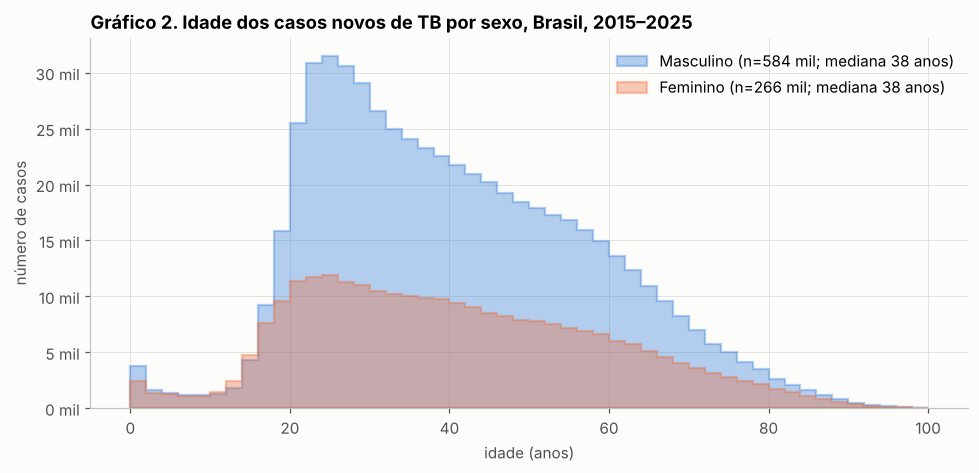

Razão de sexo (M:F) entre casos novos: 2.19


faixa_etaria,0–14,15–24,25–34,35–44,45–54,55–64,65+
sexo,,,,,,,
Feminino,4.90,18.40,20.30,17.80,14.70,11.80,12.00
Ignorado,0.00,19.60,24.70,16.50,19.60,8.20,11.30
Masculino,2.40,17.10,23.80,19.00,15.60,12.10,10.00


In [17]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, s in enumerate(["Masculino", "Feminino"]):
    x = novos.loc[novos["sexo"] == s, "idade"].astype(float).dropna()
    ax.hist(x, bins=range(0, 101, 2), histtype="stepfilled", alpha=.35, color=SERIE[i], edgecolor=SERIE[i], lw=1.5,
            label=f"{s} (n={len(x)/1000:.0f} mil; mediana {x.median():.0f} anos)")
ax.set_title("Gráfico 2. Idade dos casos novos de TB por sexo, Brasil, 2015–2025")
ax.set_xlabel("idade (anos)"); ax.set_ylabel("número de casos")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f} mil"))
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "g2_hist_idade_sexo.png"); plt.show()
razao = (novos["sexo"] == "Masculino").sum() / (novos["sexo"] == "Feminino").sum()
print(f"Razão de sexo (M:F) entre casos novos: {razao:.2f}")
novos.groupby("sexo", observed=True)["faixa_etaria"].value_counts(normalize=True).unstack().mul(100).round(1)

**Padrões observados.** A distribuição é **assimétrica à direita**, com pico entre **20 e 30 anos** e cauda longa até idades avançadas; há poucos casos em crianças (2–5% abaixo de 15 anos). Os homens são **2,2 vezes** mais numerosos que as mulheres (584 mil vs. 266 mil casos novos), e a diferença se concentra na idade adulta produtiva (20–60 anos). A mediana é a mesma (38 anos), mas as mulheres têm proporção maior em 0–14 anos (4,9% vs. 2,4%) e em 65+ anos (12,0% vs. 10,0%).

**Interpretação.** O padrão — predominância masculina e de adultos jovens — é o descrito para a TB no Brasil e no mundo e se relaciona a maior exposição (trabalho, encarceramento, uso de álcool e drogas), menor procura por serviços de saúde entre homens e maior prevalência de HIV em homens. **O gráfico não permite falar em risco**: sem população de referência por sexo e idade, não calculamos incidência; um número maior de casos não significa necessariamente maior risco individual.

### Gráfico 3 — Barras: agravos associados e populações vulneráveis
**Pergunta:** quão frequentes são comorbidades e condições de vulnerabilidade entre os casos novos?
**Por que barras horizontais:** comparar proporções entre categorias nominais com rótulos longos; o comprimento da barra é a forma mais precisa de comparar magnitudes. Denominador: casos com a variável preenchida como Sim/Não (excluídos ignorados).

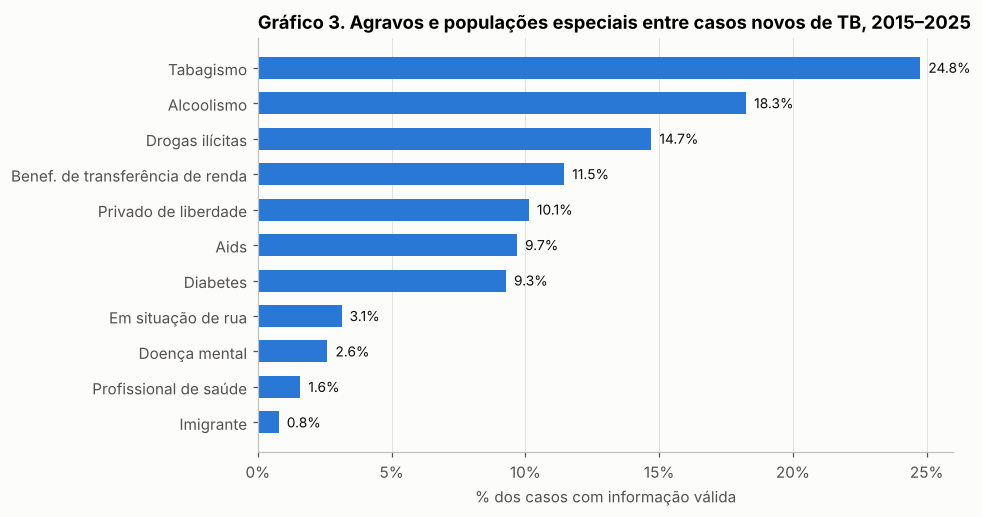

,% Sim,n válido
Imigrante,0.80,"797,961.00"
Profissional de saúde,1.60,"769,931.00"
Doença mental,2.60,"792,925.00"
Em situação de rua,3.10,"803,351.00"
Diabetes,9.30,"797,114.00"
Aids,9.70,"778,697.00"
Privado de liberdade,10.10,"809,117.00"
Benef. de transferência de renda,11.50,"507,500.00"
Drogas ilícitas,14.70,"787,626.00"
Alcoolismo,18.30,"796,966.00"


In [18]:
rotulos = {"tabagismo": "Tabagismo", "alcool": "Alcoolismo", "drogas": "Drogas ilícitas", "aids": "Aids",
           "pop_liberdade": "Privado de liberdade", "diabetes": "Diabetes", "benef_gov": "Benef. de transferência de renda",
           "pop_rua": "Em situação de rua", "doenca_mental": "Doença mental", "prof_saude": "Profissional de saúde",
           "imigrante": "Imigrante"}
prev = pd.DataFrame({r: [(novos[c] == "Sim").sum() / novos[c].isin(["Sim", "Não"]).sum() * 100,
                         novos[c].isin(["Sim", "Não"]).sum()] for c, r in rotulos.items()},
                    index=["% Sim", "n válido"]).T.sort_values("% Sim")
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(prev.index, prev["% Sim"], color=CORES["azul"], height=.62)
for y, v in enumerate(prev["% Sim"]):
    ax.text(v + .3, y, f"{v:.1f}%", va="center", fontsize=9, color=CORES["tinta"])
ax.set_title("Gráfico 3. Agravos e populações especiais entre casos novos de TB, 2015–2025")
ax.set_xlabel("% dos casos com informação válida"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.tight_layout(); fig.savefig(FIG_DIR / "g3_barras_agravos.png"); plt.show()
prev.round(1)

**Padrões observados.** Entre os agravos, **tabagismo (24,8%)**, **alcoolismo (18,3%)** e **uso de drogas ilícitas (14,7%)** são os mais frequentes; **aids (9,7%)** e **diabetes (9,3%)** vêm em seguida. Entre as populações especiais, **10,1% estão privados de liberdade** e 3,1% em situação de rua.

**Interpretação.** São frequências muito superiores às da população geral (por exemplo, a população prisional é cerca de 0,4% dos brasileiros, mas representa 1 em cada 10 casos novos de TB), o que reforça a TB como doença ligada a determinantes sociais e a comorbidades que comprometem a imunidade. **Limitações:** o denominador exclui os ignorados (5–40% conforme a variável); para *beneficiário de programa de transferência de renda* a informação válida existe para apenas ~60% dos casos (ver Função 1), então essa estimativa é a menos confiável. As variáveis são autodeclaradas e registradas pelo profissional, o que tende a **subestimar** condições estigmatizadas (drogas, álcool).

### Gráfico 4 — Boxplot: tempo de tratamento por situação de encerramento
**Pergunta:** o tempo entre o início do tratamento e o encerramento é compatível com o esquema padrão (6 meses ≈ 180 dias)? Como ele difere entre cura, abandono e óbito?
**Por que boxplot:** compara a distribuição de uma variável numérica entre grupos, mostrando mediana, dispersão (IIQ) e valores extremos de forma compacta.

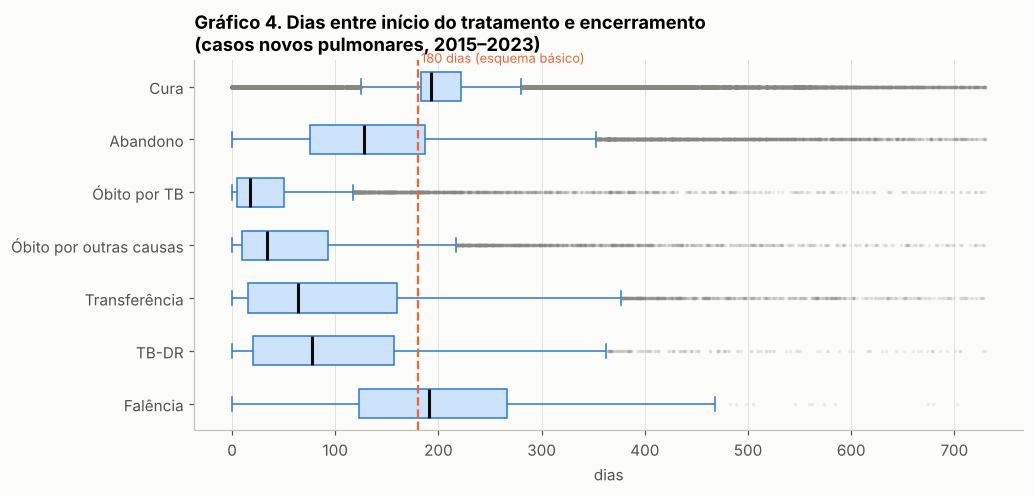

,count,25%,50%,75%
encerramento,,,,
Abandono,"68,660.00",76.00,128.00,187.00
Cura,"397,924.00",183.00,193.00,222.00
Falência,482.00,123.00,190.00,266.00
TB-DR,"4,861.00",20.00,77.00,157.00
Transferência,"27,813.00",15.00,64.00,160.00
Óbito por TB,"19,984.00",5.00,17.00,50.00
Óbito por outras causas,"21,807.00",10.00,34.00,93.00


In [19]:
ordem = ["Cura", "Abandono", "Óbito por TB", "Óbito por outras causas", "Transferência", "TB-DR", "Falência"]
dados_box = coorte[coorte["encerramento"].isin(ordem)].copy()
dados_box["encerramento"] = dados_box["encerramento"].cat.remove_unused_categories()
fig, ax = plt.subplots(figsize=(9.5, 4.6))
sns.boxplot(data=dados_box, x="tempo_trat_dias", y="encerramento", order=ordem, ax=ax, color=CORES["azul"],
            width=.55, fliersize=1.2, flierprops={"alpha": .15, "markeredgecolor": CORES["cinza"]},
            boxprops={"facecolor": "#cde2fb", "edgecolor": CORES["azul"]}, medianprops={"color": CORES["tinta"], "lw": 2},
            whiskerprops={"color": CORES["azul"]}, capprops={"color": CORES["azul"]})
ax.axvline(180, color=CORES["laranja"], ls="--", lw=1.5); ax.text(183, -0.45, "180 dias (esquema básico)", fontsize=8.5, color=CORES["laranja"])
ax.set_title("Gráfico 4. Dias entre início do tratamento e encerramento\n(casos novos pulmonares, 2015–2023)")
ax.set_xlabel("dias"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(FIG_DIR / "g4_box_tempo_encerramento.png"); plt.show()
dados_box.groupby("encerramento", observed=True)["tempo_trat_dias"].describe()[["count", "25%", "50%", "75%"]].round(0)

**Padrões observados.** Nos casos curados, a mediana é **193 dias** (IIQ 183–222), coerente com o esquema básico de 6 meses. No **abandono**, a mediana é **128 dias** (~4 meses): metade dos abandonos ocorre antes do 4º mês, justamente quando os sintomas já melhoraram. O **óbito por TB** ocorre muito cedo (mediana de **17 dias**; 75% em até 50 dias), sugerindo diagnóstico tardio, com doença avançada ao início do tratamento. Há muitos valores extremos (pontos acima de 1 ano), sobretudo em "cura".

**Interpretação.** O boxplot indica **janelas críticas**: o início do tratamento (risco de óbito) e o 2º–4º mês (risco de abandono) — onde estratégias como tratamento diretamente observado e busca de faltosos teriam mais impacto. Os valores extremos provavelmente refletem **atraso no encerramento administrativo** da ficha (a data registrada não é o fim real do tratamento) ou casos com esquema prolongado. **Limitação:** 2.574 registros com encerramento antes do início e os tempos > 730 dias foram tratados como inconsistentes e excluídos deste gráfico.

### Gráfico 5 — Mapa de calor: proporção de cura por UF e ano
**Pergunta:** quais UFs se aproximam da meta de 85% de cura e como isso mudou no tempo? Até que ano a informação de encerramento é confiável?
**Por que mapa de calor:** a matriz UF × ano tem 27 × 11 células; a cor permite ver padrões regionais e temporais de uma só vez. A escala divergente é centrada na **meta de 85%** (cinza = na meta; azul = acima; vermelho = abaixo).
Indicador (padrão MS): cura ÷ casos novos pulmonares encerrados ou não (exceto mudança de diagnóstico), por UF de residência.

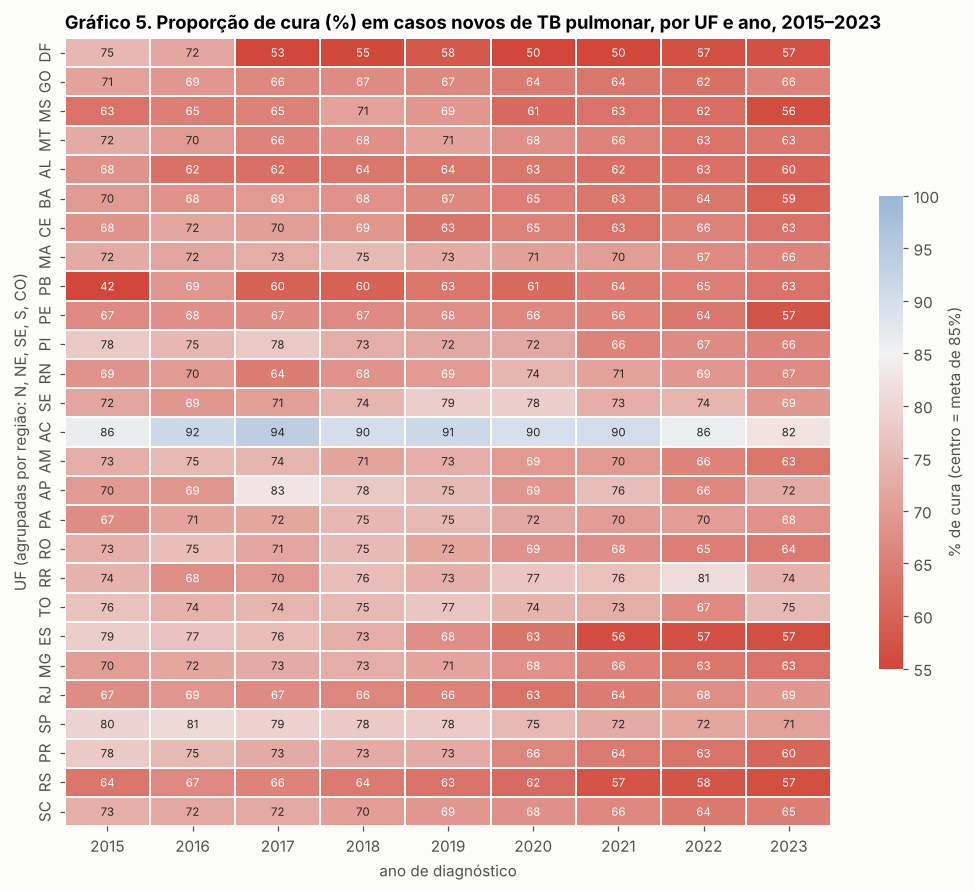

ano_diag,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
cura,71.40,72.70,71.70,71.10,70.60,68.40,66.80,66.70,65.30,62.70,32.70
abandono,10.60,10.70,11.40,12.00,12.50,13.70,14.20,14.50,15.20,15.80,10.20
obito_tb,3.70,3.60,3.80,3.80,3.60,4.10,4.50,4.60,4.80,4.80,4.30
sem_encerramento,3.80,2.70,2.80,2.50,2.70,2.90,2.70,2.70,3.20,5.10,40.20


In [20]:
def proporcao_cura(dados, por):
    g = dados.groupby(por, observed=True)
    return (g["encerramento"].apply(lambda s: (s == "Cura").mean() * 100)).unstack()

base_hm = tb[tb["caso_novo"] & tb["pulmonar"]]
hm = proporcao_cura(base_hm[base_hm["ano_diag"] <= 2023], ["uf", "ano_diag"])   # 2024–2025: encerramento incompleto
ordem_uf = (tb[["uf", "regiao"]].drop_duplicates().dropna().sort_values(["regiao", "uf"]))
ordem_uf = ordem_uf.assign(r=ordem_uf["regiao"].map({"Norte": 0, "Nordeste": 1, "Sudeste": 2, "Sul": 3, "Centro-Oeste": 4})).sort_values(["r", "uf"])
hm = hm.loc[ordem_uf["uf"]]
fig, ax = plt.subplots(figsize=(9.5, 8.2))
sns.heatmap(hm, cmap=sns.diverging_palette(15, 250, s=75, l=50, as_cmap=True), center=85, vmin=55, vmax=100,
            annot=True, fmt=".0f", annot_kws={"fontsize": 7.5}, linewidths=1, linecolor="#fcfcfb",
            cbar_kws={"label": "% de cura (centro = meta de 85%)", "shrink": .6}, ax=ax)
ax.set_title("Gráfico 5. Proporção de cura (%) em casos novos de TB pulmonar, por UF e ano, 2015–2023")
ax.set_xlabel("ano de diagnóstico"); ax.set_ylabel("UF (agrupadas por região: N, NE, SE, S, CO)")
ax.grid(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "g5_heatmap_cura_uf.png"); plt.show()

nacional = base_hm.groupby("ano_diag")["encerramento"].agg(
    cura=lambda s: (s == "Cura").mean() * 100,
    abandono=lambda s: s.isin(["Abandono", "Abandono primário"]).mean() * 100,
    obito_tb=lambda s: (s == "Óbito por TB").mean() * 100,
    sem_encerramento=lambda s: s.isna().mean() * 100)
nacional.round(1).T

**Padrões observados.**
- **Nenhuma UF** atinge a meta de 85% de forma consistente, exceto o **Acre** (86–94% em quase todos os anos).
- A cura **piora ao longo do tempo** em quase todo o país: nacionalmente, caiu de **71,4% (2015) para 65,3% (2023)**, enquanto o **abandono subiu de 10,6% para 15,2%** e o óbito por TB de 3,7% para 4,8%.
- Piores situações recentes: **DF** (50–58% desde 2017), **RS**, **ES**, **MS** e **PE** (56–57% em 2023). São Paulo, que tinha ~80%, caiu para 71%.
- Em **2024 (62,7%) e 2025 (32,7%)** a cura despenca porque **5% e 40% dos casos ainda não têm encerramento** — não é piora real, é informação incompleta. Por isso o mapa vai até 2023 e as análises de desfecho usam 2015–2023.

**Interpretação.** A queda da cura a partir de 2020 coincide com a pandemia, mas continua em 2022–2023, o que sugere problemas além do choque inicial (ex.: perda de acompanhamento, vulnerabilidade social crescente). **Cuidado:** UFs com poucos casos (AC, AP, RR) têm proporções mais instáveis de um ano para outro; e a "cura" aqui depende da qualidade do encerramento no SINAN — um caso curado mas não encerrado aparece como não curado.

## 4. Etapa 4 — Funções próprias

### Função 1 — `avaliar_incompletude`
**Finalidade:** medir a completude das variáveis do SINAN considerando, ao mesmo tempo, campos vazios **e** códigos de "ignorado", e classificar cada variável segundo o escore de Romero & Cunha (2006), muito usado para avaliar sistemas de informação em saúde: **excelente** (< 5% incompletos), **bom** (5–10%), **regular** (10–20%), **ruim** (20–50%) e **muito ruim** (≥ 50%).

**Parâmetros**
- `dados` (*DataFrame*): base a avaliar.
- `colunas` (*list*): variáveis a avaliar.
- `codigos_ignorado` (*iterable*, padrão `("Ignorado", "9")`): valores tratados como "não informado".
- `por` (*str*, opcional): se informado, calcula a incompletude total separada por grupo (ex.: ano).

**Retorno:** *DataFrame* com `n`, `% vazio`, `% ignorado`, `% incompleto` e `classificação` por variável (ou uma matriz variável × grupo, se `por` for usado).

In [21]:
def avaliar_incompletude(dados, colunas, codigos_ignorado=("Ignorado", "9"), por=None):
    """Percentual de campos vazios + ignorados e classificação de Romero & Cunha (2006)."""
    def classificar(p):
        return ("Excelente" if p < 5 else "Bom" if p < 10 else "Regular" if p < 20
                else "Ruim" if p < 50 else "Muito ruim")

    def resumo(df):
        linhas = []
        for c in colunas:
            s = df[c]
            vazio = s.isna().mean() * 100
            ign = s.astype("string").isin([str(x) for x in codigos_ignorado]).mean() * 100
            linhas.append({"variável": c, "n": len(s), "% vazio": vazio, "% ignorado": ign,
                           "% incompleto": vazio + ign, "classificação": classificar(vazio + ign)})
        return pd.DataFrame(linhas).set_index("variável")

    if por is None:
        return resumo(dados).sort_values("% incompleto", ascending=False)
    return pd.concat({g: resumo(d)["% incompleto"] for g, d in dados.groupby(por, observed=True)}, axis=1)


vars_qualidade = ["sexo", "idade", "raca", "escolaridade", "forma", "hiv_teste", "aids", "alcool", "drogas",
                  "tabagismo", "diabetes", "doenca_mental", "pop_rua", "pop_liberdade", "benef_gov",
                  "teste_molecular", "encerramento", "dt_inicio"]
incomp = avaliar_incompletude(novos, vars_qualidade)
incomp.round(1)

,n,% vazio,% ignorado,% incompleto,classificação
variável,,,,,
benef_gov,850310,27.60,12.80,40.30,Ruim
escolaridade,850310,4.20,22.20,26.40,Ruim
aids,850310,1.70,6.70,8.40,Bom
drogas,850310,2.10,5.20,7.40,Bom
teste_molecular,850310,7.00,0.00,7.00,Bom
tabagismo,850310,2.10,4.80,6.90,Bom
encerramento,850310,6.90,0.00,6.90,Bom
raca,850310,1.10,5.70,6.80,Bom
doenca_mental,850310,1.90,4.80,6.70,Bom


In [22]:
# Mesma função, agora por ano: mostra quais variáveis melhoraram/pioraram e a falta de encerramento recente
incomp_ano = avaliar_incompletude(novos, ["raca", "escolaridade", "alcool", "drogas", "benef_gov", "encerramento"],
                                  por="ano_diag")
incomp_ano.round(1)

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
variável,,,,,,,,,,,
raca,7.90,8.00,7.40,6.80,7.40,8.00,7.90,7.00,5.10,5.00,4.80
escolaridade,19.90,20.10,19.10,26.30,27.80,30.30,31.60,30.30,27.90,27.40,28.00
alcool,7.50,7.00,6.40,6.10,7.20,7.60,7.60,6.10,4.70,4.80,4.90
drogas,10.50,8.50,7.70,7.50,8.20,8.30,8.30,6.80,5.40,5.60,5.50
benef_gov,48.00,41.40,41.00,38.90,38.20,39.90,40.50,39.60,38.70,38.60,39.80
encerramento,3.90,2.80,2.90,2.60,2.70,2.90,2.70,2.70,3.20,5.10,40.30


**Resultados da Função 1.**
- **Excelente/bom** (< 10% incompleto): sexo, idade, forma clínica, resultado de HIV, início do tratamento, raça/cor, agravos e populações especiais. Isso dá segurança para usá-las nas análises.
- **Ruim** (20–50%): **escolaridade (26,4%)** e **beneficiário de transferência de renda (40,3%)**. A escolaridade **piorou** de ~20% (2015–2017) para 26–32% (2018–2025). Por isso, `benef_gov` ficou **fora** da regressão da A2, e o efeito da escolaridade deve ser lido com cautela.
- A análise por ano mostra também que o **encerramento** fica abaixo de 4% de incompletude até 2023 para **5,1% em 2024 e 40,3% em 2025** — confirma, de forma automatizada, o corte temporal usado nas análises de desfecho.
- **Reuso:** a mesma função serve para qualquer base do SINAN (dengue, sífilis…) bastando passar a lista de colunas.

### Função 2 — `comparar_desfecho`
**Finalidade:** comparar a frequência de um desfecho binário entre os níveis de uma variável categórica, gerando a tabela que epidemiologistas usam na análise bivariada: **n**, **% com desfecho**, **razão de chances (OR) bruta com IC 95%** em relação a uma categoria de referência e o **teste qui‑quadrado de independência**.

**Parâmetros**
- `dados` (*DataFrame*): base (uma linha por caso).
- `grupo` (*str*): variável explicativa categórica.
- `desfecho` (*str*, padrão `"desfecho_desfav"`): coluna 0/1.
- `referencia` (*str*, opcional): categoria de referência para a OR (padrão: a mais frequente).
- `excluir` (*tuple*, padrão `("Ignorado",)`): categorias retiradas antes do cálculo.

**Retorno:** *DataFrame* (uma linha por categoria) e, no atributo `.attrs`, a estatística χ², graus de liberdade e p‑valor.

A OR por categoria usa a tabela 2×2 (categoria vs. referência) e o IC pelo método de Woolf: `exp(ln OR ± 1,96·√(1/a + 1/b + 1/c + 1/d))`. Se alguma célula for zero, soma-se 0,5 a todas (correção de Haldane‑Anscombe), para a OR não ficar indefinida.

In [23]:
def comparar_desfecho(dados, grupo, desfecho="desfecho_desfav", referencia=None, excluir=("Ignorado",)):
    """Tabela bivariada: n, % desfecho, OR bruta (IC 95%, Woolf) vs. referência e teste qui-quadrado."""
    d = dados[[grupo, desfecho]].dropna()
    d = d[~d[grupo].astype("string").isin(excluir)]
    tab = pd.crosstab(d[grupo], d[desfecho]).reindex(columns=[0, 1], fill_value=0)
    tab = tab[tab.sum(axis=1) > 0]
    if referencia is None:
        referencia = tab.sum(axis=1).idxmax()
    c_ref, a_ref = tab.loc[referencia, 0], tab.loc[referencia, 1]   # sem / com desfecho na referência
    linhas = []
    for cat, (sem, com) in tab.iterrows():
        n = sem + com
        if cat == referencia:
            orr, li, ls = 1.0, np.nan, np.nan
        else:
            a, b_, c, d = com, sem, a_ref, c_ref
            if min(a, b_, c, d) == 0:          # célula zero: correção de Haldane-Anscombe (+0,5)
                a, b_, c, d = a + .5, b_ + .5, c + .5, d + .5
            orr = (a * d) / (b_ * c)
            ep = np.sqrt(1 / a + 1 / b_ + 1 / c + 1 / d)
            li, ls = np.exp(np.log(orr) - 1.96 * ep), np.exp(np.log(orr) + 1.96 * ep)
        linhas.append({"variável": grupo, "categoria": cat, "n": n, "% desfecho": com / n * 100,
                       "OR bruta": orr, "IC95% inf": li, "IC95% sup": ls,
                       "ref": "ref." if cat == referencia else ""})
    res = pd.DataFrame(linhas).set_index(["variável", "categoria"])
    chi2, p, gl, _ = stats.chi2_contingency(tab.values)
    res.attrs = {"qui2": chi2, "gl": gl, "p": p}
    return res


# Demonstração: desfecho desfavorável segundo situação de rua
demo = comparar_desfecho(coorte, "pop_rua", referencia="Não")
print(f"Qui-quadrado = {demo.attrs['qui2']:,.1f}; gl = {demo.attrs['gl']}; p = {demo.attrs['p']:.2e}")
demo.round(2)

Qui-quadrado = 13,649.3; gl = 1; p = 0.00e+00


n  % desfecho  OR bruta  IC95% inf  IC95% sup   ref
variável categoria                                                          
pop_rua  Não        467064       18.21      1.00        NaN        NaN  ref.
         Sim         14602       57.02      5.96       5.76       6.16

**Resultado da demonstração.** Entre pessoas **em situação de rua**, **57,0%** tiveram desfecho desfavorável, contra **18,2%** entre as demais: a chance de desfecho desfavorável é **5,96 vezes maior** (IC 95% 5,76–6,16), com associação estatisticamente significativa (χ² = 13.649; p < 0,001). Esse é o resultado **bruto** (sem ajuste para outros fatores). Na A2 a função é aplicada a **13 variáveis** em uma única linha de código, e o resultado é comparado ao modelo ajustado.

## 5. Etapa 5 — Análises

### A1 — Tendência dos casos novos e impacto da pandemia de COVID‑19
**(a) Pergunta:** quantos casos novos de TB *deixaram de ser notificados* em 2020–2021 em relação ao esperado pela tendência pré‑pandemia, e as notificações recuperaram o patamar esperado depois?

**(b) Relevância:** a TB depende de busca ativa e diagnóstico oportuno. Casos não diagnosticados continuam transmitindo e tendem a chegar mais graves aos serviços. Quantificar o "déficit" de notificações ajuda a dimensionar a demanda reprimida e a avaliar a recuperação da vigilância. A OMS documentou queda global das notificações em 2020.

**Método:** ajustamos uma **regressão linear** do número anual de casos novos em 2015–2019 (período pré‑pandemia) e projetamos o valor esperado para 2020–2025 com **intervalo de predição de 95%**. Calculamos a razão observado/esperado (O/E) e o déficit acumulado. Repetimos o cálculo por região.

In [24]:
def esperado_pre_pandemia(contagem_anual, anos_base=range(2015, 2020)):
    """Ajusta OLS (casos ~ ano) no período base e projeta todos os anos com IC de predição 95%."""
    y = contagem_anual.loc[list(anos_base)]
    X = sm.add_constant(np.array(list(anos_base), dtype=float))
    modelo = sm.OLS(y.values.astype(float), X).fit()
    anos = contagem_anual.index.values.astype(float)
    pred = modelo.get_prediction(sm.add_constant(anos)).summary_frame(alpha=.05)
    out = pd.DataFrame({"observado": contagem_anual.values, "esperado": pred["mean"].values,
                        "PI95_inf": pred["obs_ci_lower"].values, "PI95_sup": pred["obs_ci_upper"].values},
                       index=contagem_anual.index)
    out["O/E"] = out["observado"] / out["esperado"]
    out["diferença"] = out["observado"] - out["esperado"]
    return out, modelo


casos_ano = novos.groupby("ano_diag").size()
a1, modelo_a1 = esperado_pre_pandemia(casos_ano)
print(f"Tendência 2015–2019: {modelo_a1.params[1]:+,.0f} casos novos/ano (R² = {modelo_a1.rsquared:.3f}; "
      f"p = {modelo_a1.pvalues[1]:.4f})")
a1.round(2)

Tendência 2015–2019: +2,393 casos novos/ano (R² = 0.950; p = 0.0048)


,observado,esperado,PI95_inf,PI95_sup,O/E,diferença
ano_diag,,,,,,
2015,69810,"69,208.00","65,180.26","73,235.74",1.01,602.00
2016,70511,"71,600.60","67,970.04","75,231.16",0.98,"-1,089.60"
2017,73876,"73,993.20","70,505.07","77,481.33",1.00,-117.20
2018,77481,"76,385.80","72,755.24","80,016.36",1.01,"1,095.20"
2019,78288,"78,778.40","74,750.66","82,806.14",0.99,-490.40
2020,69520,"81,171.00","76,556.64","85,785.36",0.86,"-11,651.00"
2021,73094,"83,563.60","78,235.40","88,891.80",0.87,"-10,469.60"
2022,81268,"85,956.20","79,831.25","92,081.15",0.95,"-4,688.20"
2023,84779,"88,348.80","81,372.55","95,325.05",0.96,"-3,569.80"


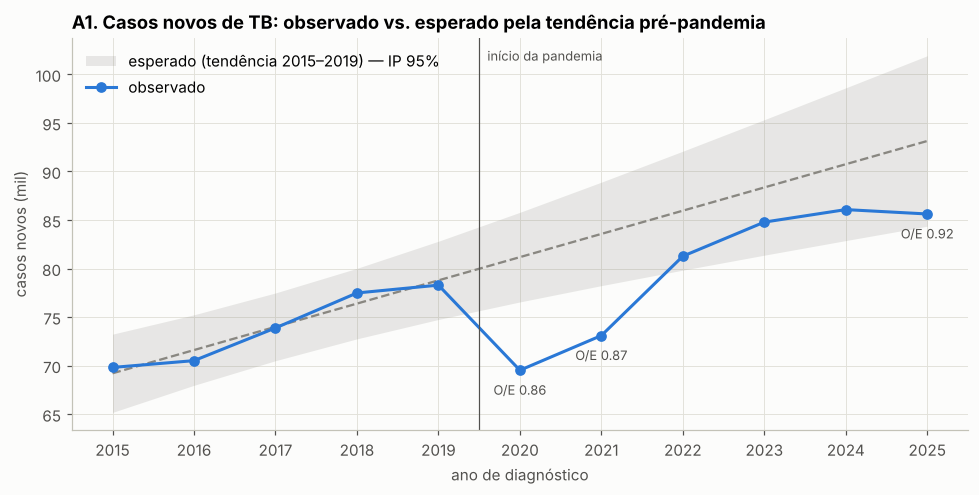

Déficit acumulado 2020–2021: 22.121 casos novos a menos que o esperado (13.4% do esperado)
Déficit acumulado 2020–2025: 42.571 casos novos
Anos com observado abaixo do limite inferior do IP 95%: [2020, 2021]


In [25]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.fill_between(a1.index, a1["PI95_inf"] / 1000, a1["PI95_sup"] / 1000, color=CORES["cinza"], alpha=.18, lw=0,
                label="esperado (tendência 2015–2019) — IP 95%")
ax.plot(a1.index, a1["esperado"] / 1000, color=CORES["cinza"], ls="--", lw=1.5)
ax.plot(a1.index, a1["observado"] / 1000, color=CORES["azul"], marker="o", ms=6, label="observado")
for ano in [2020, 2021, 2025]:
    ax.annotate(f"O/E {a1.loc[ano, 'O/E']:.2f}", (ano, a1.loc[ano, "observado"] / 1000), xytext=(0, -16),
                textcoords="offset points", ha="center", fontsize=8.5, color=CORES["tinta2"])
ax.axvline(2019.5, color=CORES["tinta2"], lw=.8); ax.text(2019.6, ax.get_ylim()[1] * .99, "início da pandemia",
                                                          fontsize=8.5, va="top", color=CORES["tinta2"])
ax.set_xticks(a1.index); ax.set_ylabel("casos novos (mil)"); ax.set_xlabel("ano de diagnóstico")
ax.set_title("A1. Casos novos de TB: observado vs. esperado pela tendência pré-pandemia")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "a1_observado_esperado.png"); plt.show()

deficit = a1.loc[[2020, 2021], "diferença"].sum()
deficit_total = a1.loc[2020:2025, "diferença"].sum()
print(f"Déficit acumulado 2020–2021: {-deficit:,.0f} casos novos a menos que o esperado "
      f"({-deficit / a1.loc[[2020, 2021], 'esperado'].sum() * 100:.1f}% do esperado)".replace(",", "."))
print(f"Déficit acumulado 2020–2025: {-deficit_total:,.0f} casos novos".replace(",", "."))
print("Anos com observado abaixo do limite inferior do IP 95%:", list(a1.index[a1["observado"] < a1["PI95_inf"]]))

In [26]:
# Por região: razão O/E em cada ano pós-2019
oe_reg = {}
for reg, d in novos.groupby("regiao", observed=True):
    r, _ = esperado_pre_pandemia(d.groupby("ano_diag").size())
    oe_reg[reg] = r["O/E"]
oe_reg = pd.DataFrame(oe_reg).T.loc[["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"], 2020:2025]
oe_reg.round(2)

ano_diag,2020,2021,2022,2023,2024,2025
Norte,0.87,0.90,0.96,0.95,0.97,0.92
Nordeste,0.84,0.87,0.94,0.92,0.89,0.85
Sudeste,0.87,0.88,0.95,0.98,0.98,0.95
Sul,0.85,0.84,0.91,0.93,0.92,0.94
Centro-Oeste,0.85,0.85,0.94,1.02,0.95,0.95


In [27]:
# Mudança no diagnóstico: uso do teste rápido molecular (TRM-TB) entre casos novos pulmonares
trm = (novos[novos["pulmonar"]].groupby("ano_diag")["teste_molecular"]
       .apply(lambda s: s.isin(["Detectável, sensível RIF", "Detectável, resistente RIF", "Não detectável",
                                "Inconclusivo"]).sum() / s.notna().sum() * 100))
print("% de casos novos pulmonares com TRM-TB realizado:\n", trm.round(1).to_string())
r_trm = stats.spearmanr(trm.loc[2015:2025].index, trm.loc[2015:2025].values)
print(f"Spearman ano × %TRM: rho = {r_trm.statistic:.2f}, p = {r_trm.pvalue:.4f}")

% de casos novos pulmonares com TRM-TB realizado:
 ano_diag
2015   29.40
2016   25.90
2017   33.10
2018   39.70
2019   42.20
2020   45.80
2021   47.50
2022   51.30
2023   56.10
2024   58.10
2025   60.80
Spearman ano × %TRM: rho = 0.99, p = 0.0000


**(c) Interpretação crítica.**
- **Antes da pandemia** os casos novos cresciam de forma quase linear: **+2.393 casos/ano** (R² = 0,95; p = 0,005).
- Em **2020 e 2021** o observado ficou **abaixo do limite inferior do intervalo de predição de 95%** (O/E = 0,86 e 0,87): cerca de **22,1 mil casos novos a menos** que o esperado nesses dois anos (−13,4%). Considerando 2020–2025, o déficit acumulado chega a **~42,6 mil casos**.
- A partir de **2022** as notificações voltaram para dentro do intervalo esperado (O/E 0,95–0,96), mas **seguem abaixo da linha de tendência** em todos os anos e, em 2025, voltaram a se afastar dela (O/E 0,92).
- A queda de 2020 foi **homogênea entre as regiões** (O/E 0,84–0,87), o que reforça uma causa nacional (pandemia) e não regional. A recuperação foi mais lenta no **Nordeste** (O/E 0,85 em 2025).
- No mesmo período, a proporção de casos novos pulmonares que fizeram **teste rápido molecular** subiu de 29% (2015) para 61% (2025) (Spearman ρ = 0,99). Uma rede diagnóstica mais sensível tenderia a **aumentar** as notificações — então o déficit não se explica por mudança no método diagnóstico.

**O que *não* podemos concluir.** (1) Não temos prova de que os ~22 mil casos "faltantes" de 2020–2021 eram pessoas com TB não diagnosticada: parte da queda pode ser real (uso de máscaras e distanciamento também reduzem a transmissão de doenças respiratórias). (2) Com apenas **5 pontos** no período‑base, a projeção linear é frágil, e extrapolar uma reta por 6 anos supõe que o crescimento continuaria — a faixa de incerteza se alarga muito em 2024–2025. (3) Os dados de 2020–2025 são preliminares. (4) Não ajustamos pelo crescimento populacional (o Censo 2022 mostrou população menor que a projetada). Ainda assim, a combinação de queda abrupta em 2020, coincidência temporal com a pandemia, homogeneidade regional e **aumento simultâneo dos reingressos e do abandono** (Gráficos 1 e 5) é consistente com o que a OMS descreveu para outros países: a pandemia reduziu o diagnóstico de TB.

### A2 — Fatores associados ao desfecho desfavorável
**(a) Pergunta:** entre casos novos de TB pulmonar diagnosticados entre 2015 e 2023, quais características se associam a maior chance de **desfecho desfavorável** (abandono, abandono primário ou óbito por TB) em comparação com a **cura**?

**(b) Relevância:** o Brasil não atinge a meta de 85% de cura (Gráfico 5), principalmente por causa do abandono. Conhecer os grupos com pior desfecho orienta estratégias focalizadas — tratamento diretamente observado, articulação com assistência social, cuidado integrado TB/HIV e redução de danos.

**Método:**
1. **Bivariada:** `comparar_desfecho` para cada fator (OR bruta + qui‑quadrado).
2. **Multivariada:** regressão logística com todos os fatores ao mesmo tempo, para estimar ORs **ajustadas** (cada uma controlada pelas demais). A idade entra padronizada (`idade_z`, Etapa 2.7). Usamos casos com informação completa (Sim/Não) nas variáveis do modelo.

Definição do desfecho: **1** = abandono, abandono primário ou óbito por TB; **0** = cura. Transferências, óbitos por outras causas, TB‑DR, mudança de esquema, falência e casos sem encerramento ficam fora (não são nem sucesso nem o desfecho de interesse, ou o desfecho é desconhecido).

In [28]:
coorte_a2 = coorte[coorte["desfecho_desfav"].notna()].copy()
coorte_a2["raca4"] = coorte_a2["raca"].astype("string").replace({"Amarela": "Amarela/Indígena", "Indígena": "Amarela/Indígena"})
coorte_a2["faixa_etaria"] = coorte_a2["faixa_etaria"].astype("string")
print(f"Coorte A2: {len(coorte_a2):,} casos | desfecho desfavorável: {coorte_a2['desfecho_desfav'].mean()*100:.1f}%".replace(",", "."))
print(coorte_a2["encerramento"].value_counts().loc[lambda s: s > 0].to_string())

fatores = {"sexo": "Feminino", "faixa_etaria": "35–44", "raca4": "Branca", "escolaridade": "Médio completo ou mais",
           "aids": "Não", "alcool": "Não", "drogas": "Não", "tabagismo": "Não", "diabetes": "Não",
           "doenca_mental": "Não", "pop_rua": "Não", "pop_liberdade": "Não", "benef_gov": "Não"}
biv = pd.concat([comparar_desfecho(coorte_a2, f, referencia=ref, excluir=("Ignorado", "Não se aplica"))
                 for f, ref in fatores.items()])
qui = pd.DataFrame({f: comparar_desfecho(coorte_a2, f, referencia=ref, excluir=("Ignorado", "Não se aplica")).attrs
                    for f, ref in fatores.items()}).T
biv.round(2)

Coorte A2: 509.305 casos | desfecho desfavorável: 19.6%
encerramento
Cura                 409529
Abandono              71130
Óbito por TB          24007
Abandono primário      4639


n  % desfecho  OR bruta  IC95% inf  IC95% sup   ref
variável      categoria                                                                            
sexo          Feminino                     153395       15.42      1.00        NaN        NaN  ref.
              Masculino                    355864       21.39      1.49       1.47       1.52      
faixa_etaria  0–14                          13967       11.40      0.47       0.44       0.49      
              15–24                         99150       18.94      0.85       0.83       0.87      
              25–34                        118908       20.52      0.93       0.92       0.95      
              35–44                         92846       21.64      1.00        NaN        NaN  ref.
              45–54                         76332       19.06      0.85       0.83       0.87      
              55–64                         59396       16.85      0.73       0.71       0.75      
              65+                           48544       21.24      0.98       0.95       1.00      
raca4         Amarela/Indígena              10051       15.83      0.93       0.88       0.99      
              Branca                       144864       16.77      1.00        NaN        NaN  ref.
              Parda                        253837       19.96      1.24       1.22       1.26      
              Preta                         65232       23.09      1.49       1.46       1.52      
escolaridade  Até fund. incompleto         200000       20.26      1.86       1.81       1.90      
              Fund. completo / médio inc.   97112       17.95      1.60       1.55       1.64      
              Médio completo ou mais        79420       12.05      1.00        NaN        NaN  ref.
aids          Não                          433727       18.22      1.00        NaN        NaN  ref.
              Sim                           29982       30.69      1.99       1.94       2.04      
alcool        Não                          388867       16.42      1.00        NaN        NaN  ref.
              Sim                           90003       30.54      2.24       2.20       2.27      
drogas        Não                          400861       16.20      1.00        NaN        NaN  ref.
              Sim                           72522       34.34      2.70       2.66       2.75      
tabagismo     Não                          353197       16.43      1.00        NaN        NaN  ref.
              Sim                          122649       26.53      1.84       1.81       1.86      
diabetes      Não                          433236       19.29      1.00        NaN        NaN  ref.
              Sim                           44960       16.03      0.80       0.78       0.82      
doenca_mental Não                          464638       18.79      1.00        NaN        NaN  ref.
              Sim                           11661       25.81      1.50       1.44       1.57      
pop_rua       Não                          467064       18.21      1.00        NaN        NaN  ref.
              Sim                           14602       57.02      5.96       5.76       6.16      
pop_liberdade Não                          428949       20.18      1.00        NaN        NaN  ref.
              Sim                           56405       13.34      0.61       0.59       0.62      
benef_gov     Não                          269798       19.03      1.00        NaN        NaN  ref.
              Sim                           33442       17.34      0.89       0.87       0.92

In [29]:
qui.assign(p=qui["p"].map(lambda p: f"{p:.1e}")).round({"qui2": 1})

,qui2,gl,p
sexo,"2,418.90",1.00,0.0e+00
faixa_etaria,"1,313.60",6.00,1.2e-280
raca4,"1,342.40",3.00,9.1e-291
escolaridade,"2,607.40",2.00,0.0e+00
aids,"2,828.20",1.00,0.0e+00
alcool,"9,428.30",1.00,0.0e+00
drogas,"13,131.70",1.00,0.0e+00
tabagismo,"6,020.50",1.00,0.0e+00
diabetes,282.80,1.00,1.8e-63
doenca_mental,365.20,1.00,2.1e-81


In [30]:
# Regressão logística multivariada (casos completos). Ignorados excluídos; escolaridade "Não se aplica" excluída.
vars_mod = ["sexo", "idade_z", "raca4", "escolaridade", "aids", "alcool", "drogas", "tabagismo", "diabetes",
            "doenca_mental", "pop_rua", "pop_liberdade"]
m = coorte_a2[["desfecho_desfav"] + vars_mod].copy()
for c in vars_mod:
    if c != "idade_z":
        m[c] = m[c].astype("string")
        m = m[~m[c].isin(["Ignorado", "Não se aplica"])]
m = m.dropna()
formula = ("desfecho_desfav ~ C(sexo, Treatment('Feminino')) + idade_z + I(idade_z**2)"
           " + C(raca4, Treatment('Branca')) + C(escolaridade, Treatment('Médio completo ou mais'))"
           + "".join(f" + C({v}, Treatment('Não'))" for v in vars_mod[4:]))
logit = smf.logit(formula, data=m).fit(disp=False)
b1, b2 = logit.params["idade_z"], logit.params["I(idade_z ** 2)"]
print(f"Idade com menor chance prevista (vértice da parábola): {mu + (-b1 / (2 * b2)) * sd:.0f} anos")
print(f"n no modelo = {int(logit.nobs):,} ({logit.nobs / len(coorte_a2) * 100:.1f}% da coorte A2) | "
      f"pseudo-R² McFadden = {logit.prsquared:.3f}".replace(",", "."))

NOMES = {"sexo": "Sexo", "raca4": "Raça/cor", "escolaridade": "Escolaridade", "aids": "Aids", "alcool": "Alcoolismo",
         "drogas": "Drogas ilícitas", "tabagismo": "Tabagismo", "diabetes": "Diabetes", "doenca_mental": "Doença mental",
         "pop_rua": "Situação de rua", "pop_liberdade": "Privado de liberdade"}
REFS = {"sexo": "feminino", "raca4": "branca", "escolaridade": "médio completo ou mais"}

def nome_bonito(t):
    """Converte o nome do coeficiente do statsmodels em rótulo legível."""
    if t == "idade_z": return "Idade (por +1 DP ≈ 17 anos)"
    if t.startswith("I(idade"): return "Idade² (termo quadrático)"
    m_ = re.match(r"C\((\w+),.*\)\[T\.(.+)\]", t)
    if not m_: return t
    v, cat = m_.groups()
    if v in REFS: return f"{NOMES[v]}: {cat.lower()} (ref. {REFS[v]})"
    return f"{NOMES[v]} (sim vs. não)"

or_aj = pd.DataFrame({"OR ajustada": np.exp(logit.params), "IC95% inf": np.exp(logit.conf_int()[0]),
                      "IC95% sup": np.exp(logit.conf_int()[1]), "p": logit.pvalues}).drop("Intercept")
or_aj.index = [nome_bonito(i) for i in or_aj.index]
or_aj.round(3)

Idade com menor chance prevista (vértice da parábola): 47 anos
n no modelo = 316.589 (62.2% da coorte A2) | pseudo-R² McFadden = 0.060


,OR ajustada,IC95% inf,IC95% sup,p
Sexo: masculino (ref. feminino),1.30,1.27,1.33,0.00
Raça/cor: amarela/indígena (ref. branca),0.97,0.90,1.05,0.42
Raça/cor: parda (ref. branca),1.20,1.17,1.23,0.00
Raça/cor: preta (ref. branca),1.34,1.30,1.38,0.00
Escolaridade: até fund. incompleto (ref. médio completo ou mais),1.53,1.49,1.57,0.00
Escolaridade: fund. completo / médio inc. (ref. médio completo ou mais),1.40,1.36,1.45,0.00
Aids (sim vs. não),1.69,1.63,1.75,0.00
Alcoolismo (sim vs. não),1.31,1.28,1.35,0.00
Drogas ilícitas (sim vs. não),1.99,1.93,2.04,0.00
Tabagismo (sim vs. não),1.26,1.23,1.29,0.00


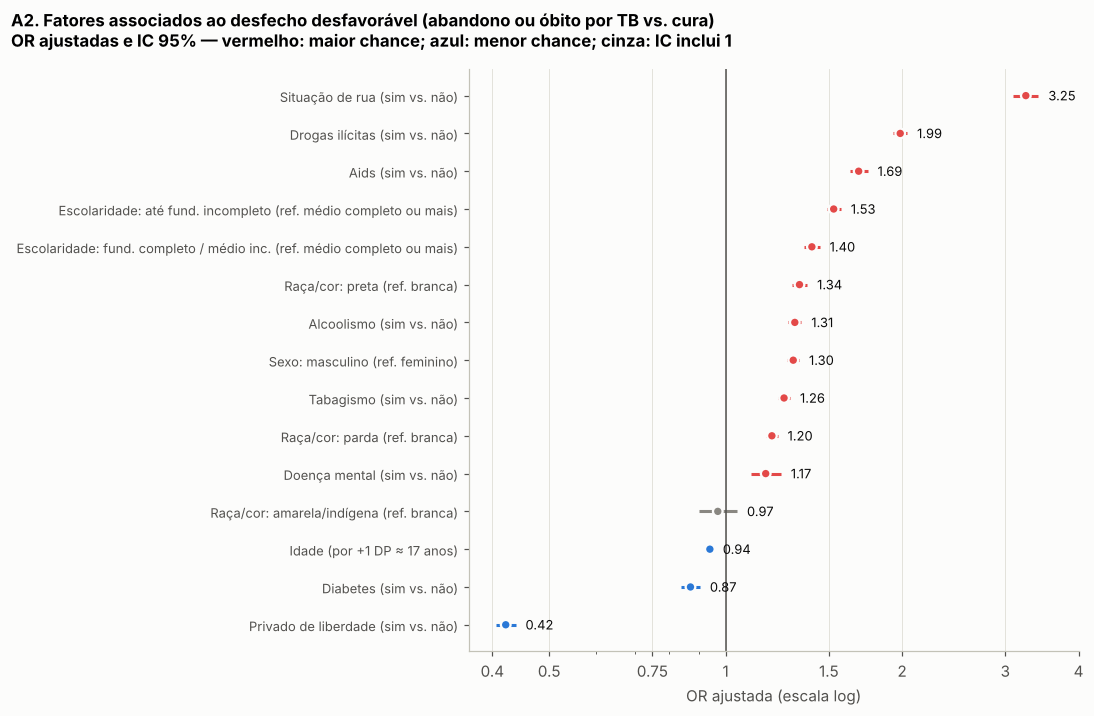

In [31]:
plot_or = or_aj.drop("Idade² (termo quadrático)").sort_values("OR ajustada")
fig, ax = plt.subplots(figsize=(10, 6.6))
y = np.arange(len(plot_or))
cor = np.where(plot_or["IC95% inf"] > 1, CORES["vermelho"], np.where(plot_or["IC95% sup"] < 1, CORES["azul"], CORES["cinza"]))
ax.hlines(y, plot_or["IC95% inf"], plot_or["IC95% sup"], color=cor, lw=2)
ax.scatter(plot_or["OR ajustada"], y, color=cor, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
for yi, (v, sup) in enumerate(zip(plot_or["OR ajustada"], plot_or["IC95% sup"])):
    ax.text(sup * 1.04, yi, f"{v:.2f}", va="center", fontsize=8.5, color=CORES["tinta"])
ax.axvline(1, color=CORES["tinta2"], lw=1)
ax.set_xscale("log"); ax.set_xticks([0.4, 0.5, 0.75, 1, 1.5, 2, 3, 4]); ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%g"))
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_yticks(y); ax.set_yticklabels(plot_or.index, fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("OR ajustada (escala log)")
fig.suptitle("A2. Fatores associados ao desfecho desfavorável (abandono ou óbito por TB vs. cura)\n"
             "OR ajustadas e IC 95% — vermelho: maior chance; azul: menor chance; cinza: IC inclui 1",
             x=.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "a2_forest_or.png"); plt.show()

In [32]:
# Probabilidade prevista de desfecho desfavorável por número de vulnerabilidades (álcool, drogas, rua, aids)
m["n_vulnerab"] = (m[["alcool", "drogas", "pop_rua", "aids"]] == "Sim").sum(axis=1)
grad = m.groupby("n_vulnerab")["desfecho_desfav"].agg(n="size", pct=lambda s: s.mean() * 100)
grad["previsto_modelo_%"] = m.assign(p=logit.predict(m)).groupby("n_vulnerab")["p"].mean() * 100
print(f"Tendência linear (Spearman, nível individual): rho = {stats.spearmanr(m['n_vulnerab'], m['desfecho_desfav']).statistic:.3f}")
grad.round(1)

Tendência linear (Spearman, nível individual): rho = 0.194


,n,pct,previsto_modelo_%
n_vulnerab,,,
0,221404,12.80,13.10
1,64282,23.60,21.60
2,25300,32.90,33.40
3,5036,49.60,54.80
4,567,61.90,72.60


**(c) Interpretação crítica.**

*Coorte:* 509.305 casos novos de TB pulmonar (2015–2023) com desfecho cura ou desfavorável; **19,6%** tiveram desfecho desfavorável (abandono 14,0%, óbito por TB 4,7%, abandono primário 0,9%). O modelo multivariado usou 316.589 casos com todas as variáveis preenchidas (62%).

*Principais achados (OR ajustada, IC 95%):*
- **Situação de rua** é o fator mais forte: OR bruta 5,96 → **ajustada 3,25** (3,10–3,42). A queda da OR mostra que parte do efeito bruto se deve à sobreposição com uso de drogas, álcool e baixa escolaridade — mas o efeito permanece grande mesmo após o ajuste.
- **Uso de drogas ilícitas** (1,99), **aids** (1,69), **baixa escolaridade** (1,53 para até fundamental incompleto vs. médio completo), **raça/cor preta** (1,34) e **parda** (1,20), **alcoolismo** (1,31), **sexo masculino** (1,30), **tabagismo** (1,26) e **doença mental** (1,17) também se associam a maior chance de desfecho desfavorável.
- **Efeito acumulado:** a proporção de desfecho desfavorável sobe de **12,8%** (nenhuma das vulnerabilidades álcool/drogas/rua/aids) para **23,6%** (1), **32,9%** (2), **49,6%** (3) e **61,9%** (4) — um gradiente claro.
- **Associações "protetoras":** **privados de liberdade** (OR 0,42) e **diabetes** (0,87) têm *menor* chance de desfecho desfavorável. A explicação mais plausível **não** é que a prisão ou o diabetes "protejam": no sistema prisional o tratamento costuma ser supervisionado e é difícil abandonar; pessoas com diabetes já estão vinculadas a um serviço de saúde e tendem a ser mais velhas e acompanhadas. Isso ilustra por que **associação não é causalidade**.
- **Idade:** relação não linear (termo quadrático significativo, OR 1,08). No modelo ajustado, a menor chance ocorre por volta dos **47 anos**, aumentando nos mais jovens (em quem pesa o abandono) e, sobretudo, nos idosos (em quem pesa o óbito por TB). Na análise bruta, crianças de 0–14 anos têm a menor proporção (11,4%).

*Cautela na interpretação:*
1. **Não é causal.** O desenho é observacional; variáveis não medidas (renda, distância até o serviço, apoio familiar, tipo de serviço, TDO) podem explicar parte das associações (confundimento residual).
2. Com ~300 mil observações, **qualquer diferença pequena vira "significativa"** (p < 0,001 em quase tudo). Por isso, olhamos o **tamanho do efeito** (OR e IC), não apenas o p‑valor.
3. O pseudo‑R² de McFadden (0,06) é baixo: os fatores ajudam a identificar grupos de risco, mas **não predizem bem** o desfecho de um indivíduo.
4. Juntar abandono e óbito em um único desfecho simplifica fenômenos com causas diferentes; uma extensão natural seria modelá‑los separadamente (regressão multinomial).
5. A análise de casos completos exclui 38% da coorte; se a falta de informação estiver ligada ao desfecho (ex.: serviços com pior registro também têm mais abandono), as ORs podem estar enviesadas.

**Implicação para a saúde pública:** os grupos com maior chance de desfecho desfavorável — população em situação de rua, pessoas que usam álcool e drogas, pessoas vivendo com HIV/aids, pessoas com baixa escolaridade e população negra — são justamente os que mais dependem de **proteção social e cuidado intersetorial** (Consultório na Rua, CAPS‑AD, serviços de HIV, TDO, benefícios sociais).

## 6. Conclusões e limitações
### Principais achados
1. **Perfil:** a TB no Brasil (2015–2025, 850 mil casos novos) atinge principalmente **homens (69%)**, **adultos jovens** (pico 20–30 anos) e **pessoas pardas e pretas** (64% das notificações), com alta frequência de tabagismo, álcool, drogas, aids e privação de liberdade.
2. **Pandemia (A1):** em 2020–2021 houve **~22 mil casos novos a menos** que o esperado pela tendência anterior (−13%), queda observada em todas as regiões. As notificações voltaram a crescer a partir de 2022, mas seguem **abaixo da tendência pré‑pandemia**.
3. **Piora do tratamento:** a cura caiu de **71% para 65%** (2015→2023) e o abandono subiu de **11% para 15%** — muito longe das metas de 85% e 5%. Os **reingressos após abandono** mais que dobraram (7,3 mil → 17,0 mil/ano).
4. **Fatores associados (A2):** situação de rua (OR ajustada 3,3), uso de drogas (2,0), aids (1,7), baixa escolaridade (1,5), raça/cor preta (1,3) e sexo masculino (1,3) se associam a maior chance de abandono/óbito; o risco cresce com o número de vulnerabilidades (13% → 62%).
5. **Qualidade dos dados:** as variáveis centrais têm completude boa/excelente, mas escolaridade e benefício social são ruins, e o encerramento de 2024–2025 ainda é incompleto.

### Limitações
- **Dados preliminares** em 2020–2025 e **encerramento incompleto** em 2024–2025.
- **Unidade = notificação**, não pessoa: sem identificador, não é possível ligar transferências e reingressos ao mesmo indivíduo.
- **Sem denominador populacional:** trabalhamos com contagens e proporções; não calculamos taxas de incidência.
- **Subnotificação e sub-registro** de condições estigmatizadas; o código "Ignorado" e o "0" de 2015–2017 exigiram decisões de tratamento que podem afetar estimativas.
- **Desenho observacional:** associações não implicam causalidade; há confundimento residual.
- **Projeção linear** com só 5 pontos no período‑base é uma aproximação simples.

### Próximos passos possíveis
Calcular **taxas de incidência** com população do IBGE; analisar abandono e óbito **separadamente**; incluir variáveis de serviço (TDO, tipo de unidade); e usar modelos de séries temporais (ex.: ARIMA ou regressão segmentada com dados mensais) para estimar o efeito da pandemia com mais precisão.

### Referências
- Brasil. Ministério da Saúde. *Boletim Epidemiológico — Tuberculose 2025*. Secretaria de Vigilância em Saúde e Ambiente.
- Brasil. Ministério da Saúde. *Brasil Livre da Tuberculose: Plano Nacional pelo Fim da Tuberculose como Problema de Saúde Pública — estratégias para 2021–2025*.
- World Health Organization. *Global Tuberculosis Report*. Genebra: WHO (edições 2021–2025).
- Romero DE, Cunha CB. Avaliação da qualidade das variáveis sócio-econômicas e demográficas dos óbitos de crianças menores de um ano registrados no SIM do Brasil (1996/2001). *Cad Saúde Pública*. 2006;22(3):673‑684.
- DATASUS. Dicionário de dados — SINAN Tuberculose (ficha de notificação/investigação).

In [33]:
import sys, platform, matplotlib, scipy, statsmodels, seaborn
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", seaborn.__version__, "| scipy", scipy.__version__,
      "| statsmodels", statsmodels.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1 | statsmodels 0.15.0
